# Figures of the Perspective "Uncertainty-aware digital rheology beyond curve fitting"

This notebook contains all the code behind the six figures of the paper, in the order in which they appear:

1. Uncertainty-aware digital rheology as a closed measurement–inference loop
2. Identifiability of a thixotropic model learned with rheology-informed neural networks (RhINNs)
3. Gaussian processes in rheology: superposition, raw-signal inference and LAOS
4. Model discrepancy and correlated residuals in raw-time-series inference
5. Shampoo formulations: rheological fingerprint space and uncertainty-aware classification
6. A generalized Maxwell spectrum calibrated on a restricted window, and the value of the next experiment

**Reproducibility.** Every number in the figures is computed in this notebook from the raw data in `data/`; nothing is imported from unpublished code. Expensive steps (nested sampling, network training, GP fits) are written as functions that store their output in `results/` and reuse it on the next run. Deleting `results/` and running the notebook recomputes everything from scratch in about one hour on a laptop CPU (run times are given in each section); keeping it redraws the figures from the stored results in about a minute. All random steps use fixed seeds, and a from-scratch run reproduces the stored results.

**Data** (`data/`):

| File | Content | Used in |
|---|---|---|
| `PS_LVE_ShanbhagRicarte.xlsx` | polystyrene SAOS, relaxation and creep at 130–190 °C (Shanbhag/Ricarte, *Polym. Chem.*, supplementary workbook) | Figs. 1, 3a, 6 |
| `micelles/*.xlsx` | raw strain and stress of one 3 s and two 15 s chirps on a wormlike-micelle solution (Das et al.; RheoGP demo data) | Figs. 1, 3b, 4 |
| `cnf_laos_1.0wt/*.csv` | raw LAOS waveforms of a 1 wt% cellulose-nanofibril suspension, 21 strain amplitudes | Fig. 3c |
| `chia_pudding/oscillation_chia_data.csv` | SAOS of a chia-seed pudding (pyRheo demo data) | Fig. 1 |
| `Chitre2024_LiquidFormulationsDataset.json` | 812 shampoo formulations with composition, stability and flow curves (Chitre et al., *Sci. Data* 2024, CC0) | Fig. 5 |

**Environment.** Python 3.10 with numpy 2.2, scipy 1.15, pandas 2.3, matplotlib 3.10, SciencePlots 2.2, scikit-learn 1.7, dynesty 3.1, torch 2.13, gpytorch 1.15, botorch 0.16 and mastercurves 0.2.3, plus two public packages from GitHub: `rheogp` v1.1.0 (`pip install git+https://github.com/mirandi1/rheogp@v1.1.0`) and `pyRheo` (`pip install git+https://github.com/mirandi1/pyRheo@9435084`). The exact environment is in `environment.yml`. A LaTeX installation is needed for the figure text. Run from the repository root.

## Setup and shared figure style

All figures share one style: SciencePlots `["science", "nature", "bright"]`, LaTeX sans-serif text, RSC column widths (single 8.3 cm, double 17.1 cm), units in brackets, and a labeled major tick at every decade on log axes. `panel` adds the bold panel letter and `save` writes PDF and PNG.

In [1]:
%matplotlib inline
import os
import json
import pickle
import zlib
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import scienceplots  # noqa: F401  (registers the SciencePlots styles)
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = os.getcwd()                                  # repository root
DATA_DIR = os.path.join(ROOT, "data")
RESULTS = os.path.join(ROOT, "results")
FIGURES = os.path.join(ROOT, "figures")
os.makedirs(FIGURES, exist_ok=True)

DOUBLE = 6.7    # in, RSC double-column width (17.1 cm)
SINGLE = 3.3    # in, RSC single-column width (8.3 cm)

# Paul Tol "bright" palette (color-blind safe)
BLUE, RED, GREEN, YELLOW, CYAN, PURPLE, GREY = (
    "#4477AA", "#EE6677", "#228833", "#CCBB44", "#66CCEE", "#AA3377", "#BBBBBB")
INK = "#222222"


def use_style():
    plt.style.use(["science", "nature", "bright"])
    mpl.rcParams.update({
        "text.usetex": True,
        "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{sfmath}",
        "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
        "legend.fontsize": 6, "legend.handlelength": 1.6, "legend.borderaxespad": 0.3,
        "axes.grid": False, "savefig.dpi": 600, "figure.dpi": 150,
        "pdf.fonttype": 42, "lines.markersize": 2.5,
    })


def panel(ax, letter, x=-0.02, y=1.02):
    ax.text(x, y, rf"\textbf{{{letter}}}", transform=ax.transAxes, fontsize=8, ha="right", va="bottom")


def every_decade(fig):
    """Major tick and label at every decade on every log axis (no skipped decades)."""
    from matplotlib.ticker import LogLocator, LogFormatterSciNotation, NullFormatter
    for ax in fig.get_axes():
        if getattr(ax, "keep_ticks", False):
            continue
        for axis, scale in ((ax.xaxis, ax.get_xscale()), (ax.yaxis, ax.get_yscale())):
            if scale != "log":
                continue
            axis.set_major_locator(LogLocator(base=10, numticks=100))
            axis.set_major_formatter(LogFormatterSciNotation(base=10, labelOnlyBase=True))
            axis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
            axis.set_minor_formatter(NullFormatter())


def save(fig, name, decades=True):
    if decades:
        every_decade(fig)
    path = os.path.join(FIGURES, name)
    fig.savefig(path + ".pdf")
    fig.savefig(path + ".png", dpi=400)


def show(fig):
    """Display a finished figure once and release it."""
    display(fig)
    plt.close(fig)

## Shared data: polystyrene linear viscoelasticity

Figures 1, 3 and 6 use the polystyrene melt dataset of the Shanbhag/Ricarte tutorial review (*Polym. Chem.*, supplementary workbook `data/PS_LVE_ShanbhagRicarte.xlsx`): SAOS, stress relaxation and creep, each measured at 130, 145, 160, 175 and 190 °C. Only the unshifted columns are read; any superposition is done in this notebook.

In [2]:
PS_XLSX = os.path.join(DATA_DIR, "PS_LVE_ShanbhagRicarte.xlsx")
TEMPS = [130, 145, 160, 175, 190]


def _ps_block(sheet, ncols, stride):
    df = pd.read_excel(PS_XLSX, sheet_name=sheet, header=None)
    out = {}
    for i, T in enumerate(TEMPS):
        b = df.iloc[3:, i * stride:i * stride + ncols].apply(pd.to_numeric, errors="coerce").dropna()
        out[T] = b.to_numpy(float)
    return out


def load_ps():
    """Returns (saos, relax, creep), each a dict keyed by temperature in deg C."""
    saos = {T: dict(w=a[:, 0], Gp=a[:, 1], Gpp=a[:, 2]) for T, a in _ps_block("SAOS Data", 3, 8).items()}
    relax = {T: dict(t=a[:, 0], G=a[:, 1]) for T, a in _ps_block("Stress Relaxation Data", 2, 5).items()}
    creep = {T: dict(t=a[:, 0], J=a[:, 1]) for T, a in _ps_block("Creep Data", 2, 5).items()}
    return saos, relax, creep


PS_SAOS, PS_RELAX, PS_CREEP = load_ps()
for T in TEMPS:
    w = PS_SAOS[T]["w"]
    print(f"{T} C: SAOS {len(w)} points, omega = {w.min():.3g}-{w.max():.3g} rad/s; "
          f"creep {len(PS_CREEP[T]['t'])} points up to {PS_CREEP[T]['t'].max():.0f} s")

130 C: SAOS 32 points, omega = 0.01-300 rad/s; creep 28799 points up to 28830 s
145 C: SAOS 32 points, omega = 0.01-300 rad/s; creep 7199 points up to 7208 s
160 C: SAOS 32 points, omega = 0.01-300 rad/s; creep 3599 points up to 3605 s
175 C: SAOS 32 points, omega = 0.01-300 rad/s; creep 3599 points up to 3605 s
190 C: SAOS 32 points, omega = 0.01-300 rad/s; creep 3598 points up to 3605 s


## Shared models

Three models appear in more than one figure and are defined once here.

**Thixotropic structural kinetics** (Figs. 1 and 2). An inelastic thixotropic yield-stress fluid (Moore / Mewis–Wagner type) with a structure parameter $\lambda\in[0,1]$:

$$\sigma=\sigma_y\lambda+\eta_\infty\dot\gamma,\qquad \frac{d\lambda}{dt}=k_+(1-\lambda)-k_-\lambda\dot\gamma ,$$

with true parameters $\sigma_y=10$ Pa, $\eta_\infty=0.1$ Pa s, $k_+=0.1$ s⁻¹ and $k_-=0.05$. At steady state $\lambda_{ss}=1/(1+(k_-/k_+)\dot\gamma)$. Transients are integrated with SciPy (LSODA, relative tolerance $10^{-10}$).

In [3]:
from scipy.integrate import solve_ivp

TRUTH = dict(sigma_y=10.0, eta_inf=0.1, k_plus=0.1, k_minus=0.05)


def lam_ss(gdot, p):
    """Steady-state structure parameter."""
    return 1.0 / (1.0 + p["k_minus"] / p["k_plus"] * gdot)


def simulate(gdot_fun, t_eval, lam0, p):
    """Integrates the structure kinetics for a shear-rate history gdot_fun(t); returns lambda(t), sigma(t)."""
    def rhs(t, y):
        return [p["k_plus"] * (1 - y[0]) - p["k_minus"] * y[0] * gdot_fun(t)]
    sol = solve_ivp(rhs, (0, t_eval[-1]), [lam0], t_eval=t_eval, method="LSODA",
                    rtol=1e-10, atol=1e-12, max_step=0.05)
    lam = sol.y[0]
    g = np.array([gdot_fun(tt) for tt in t_eval])
    return lam, p["sigma_y"] * lam + p["eta_inf"] * g


def loop_protocol(T=120.0, gmax=10.0):
    """Hysteresis loop: linear shear-rate ramp 0 -> gmax -> 0 over T seconds."""
    return lambda t: gmax * (t / (T / 2)) if t <= T / 2 else gmax * max(0.0, 2 - t / (T / 2))

**Generalized Maxwell spectrum** (Figs. 1 and 6). Eleven modes on a fixed grid $\tau_i=10^{-5},10^{-4},\ldots,10^{5}$ s:

$$G'(\omega)=\sum_i G_i\frac{(\omega\tau_i)^2}{1+(\omega\tau_i)^2},\qquad G''(\omega)=\sum_i G_i\frac{\omega\tau_i}{1+(\omega\tau_i)^2},\qquad G(t)=\sum_i G_i e^{-t/\tau_i},\qquad \eta_0=\sum_i G_i\tau_i .$$

The creep compliance $J(t)$ is computed exactly from the eigen-solution of the stress-controlled mode equations. The strengths are inferred for polystyrene at 145 °C by nested sampling (`dynesty`; 600 live points, multi-ellipsoid bounds, random slice sampling, stop at $\Delta\ln Z<0.1$) with uniform priors $\log_{10}G_i\in[0,8]$ and a Gaussian likelihood on the log-residuals of $G'$, $G''$ (and, when used, $J$) with an unknown scatter per data type, $\log_{10}\sigma\in[-2.5,0]$. Two calibrations are run: SAOS alone, and SAOS together with 40 log-spaced points of the measured 2 h creep compliance.

In [4]:
import dynesty
from dynesty import utils as dyfunc

GM_DIR = os.path.join(RESULTS, "fig2_gm")
GM_T = 145
TAU = np.logspace(-5, 5, 11)        # one mode per decade
LOG_G = (0.0, 8.0)                  # prior on log10 G_i [Pa]
LOG_SIG = (-2.5, 0.0)               # prior on log10 scatter of the log-residuals


def gm_moduli(G, tau, w):
    wt = np.outer(w, tau)
    return (G * wt**2 / (1 + wt**2)).sum(1), (G * wt / (1 + wt**2)).sum(1)


def gm_relax(G, tau, t):
    return (G[None, :] * np.exp(-np.outer(t, 1 / tau))).sum(1)


def gm_creep(G, tau, t, Ge=0.0):
    """Exact creep compliance of a Prony series (eigen-solution of the stress-controlled mode equations)."""
    G = np.asarray(G, float); tau = np.asarray(tau, float)
    Gtot = Ge + G.sum()
    wv = (1.0 / tau) / Gtot
    A = np.outer(G, wv) - np.diag(1.0 / tau)
    lam, V = np.linalg.eig(A)
    c = np.linalg.solve(V, G / Gtot)
    coef = (wv @ V) * c
    tt = np.atleast_1d(t)[:, None]
    lam = lam[None, :]
    small = np.abs(lam) < 1e-14 * np.abs(lam).max()
    integ = np.where(small, tt, (np.exp(lam * tt) - 1.0) / np.where(small, 1.0, lam))
    return np.real(1.0 / Gtot + (integ * coef[None, :]).sum(1))


def gm_data(T=GM_T, n_creep=40):
    """SAOS at temperature T and the creep record thinned to n_creep log-spaced points."""
    t, J = PS_CREEP[T]["t"], PS_CREEP[T]["J"]
    idx = np.unique(np.searchsorted(t, np.logspace(np.log10(t[0]), np.log10(t[-1]), n_creep)).clip(0, len(t) - 1))
    return dict(saos=dict(w=PS_SAOS[T]["w"], Gp=PS_SAOS[T]["Gp"], Gpp=PS_SAOS[T]["Gpp"]),
                creep=dict(t=t[idx], J=J[idx]), creep_full=dict(t=t, J=J))


def gauss_loglike(r, lsig):
    s = 10.0 ** lsig
    return -0.5 * np.sum((r / s) ** 2) - r.size * (np.log(s) + 0.5 * np.log(2 * np.pi))


def gm_run(use_creep, nlive=600, seed=None):
    """Nested sampling of the 11-mode spectrum on SAOS (and creep); seed=None is the main run, integers give repeats."""
    tag = f"T{GM_T}_liquid_{'both' if use_creep else 'saos'}" + ("" if seed is None else f"_nl{nlive}_s{seed}")
    fn = os.path.join(GM_DIR, tag + ".pkl")
    if os.path.exists(fn):
        return pickle.load(open(fn, "rb"))
    d = gm_data()
    n = TAU.size; ndim = n + (2 if use_creep else 1)
    w, lGp, lGpp = d["saos"]["w"], np.log(d["saos"]["Gp"]), np.log(d["saos"]["Gpp"])
    tc, lJ = d["creep"]["t"], np.log(d["creep"]["J"])

    def prior(u):
        x = LOG_G[0] + u * (LOG_G[1] - LOG_G[0])
        x[n:] = LOG_SIG[0] + u[n:] * (LOG_SIG[1] - LOG_SIG[0])
        return x

    def loglike(th):
        G = 10 ** th[:n]
        a, b = gm_moduli(G, TAU, w)
        out = gauss_loglike(np.r_[np.log(a) - lGp, np.log(b) - lGpp], th[n])
        if use_creep:
            with np.errstate(all="ignore"):
                r = np.log(gm_creep(G, TAU, tc)) - lJ
            out += gauss_loglike(np.where(np.isfinite(r), r, 30.0), th[n + 1])
        return out

    rs = np.random.default_rng(zlib.crc32(f"liquid{use_creep}".encode()) if seed is None else 2000 + seed)
    smp = dynesty.NestedSampler(loglike, prior, ndim, nlive=nlive, bound="multi", sample="rslice", rstate=rs)
    smp.run_nested(dlogz=0.1, print_progress=False)
    r = smp.results
    eq = dyfunc.resample_equal(r.samples, np.exp(r.logwt - r.logz[-1]), rstate=np.random.default_rng(1))
    out = dict(key="liquid", use_creep=use_creep, logz=float(r.logz[-1]), logzerr=float(r.logzerr[-1]), samples=eq)
    os.makedirs(GM_DIR, exist_ok=True)
    pickle.dump(out, open(fn, "wb"))
    return out


def gm_band(smp, kind, x, n=400):
    """Posterior 2.5, 50 and 97.5 percentiles of G', G'' or J at x, from n posterior draws."""
    idx = np.random.default_rng(0).choice(len(smp), min(n, len(smp)), replace=False)
    Y = []
    for i in idx:
        G = 10 ** smp[i][:TAU.size]
        if kind == "J":
            Y.append(gm_creep(G, TAU, x))
        else:
            a, b = gm_moduli(G, TAU, x); Y.append(a if kind == "Gp" else b)
    return np.nanpercentile(np.array(Y), [2.5, 50, 97.5], 0)


GM_D = gm_data()

**Fractional Maxwell liquid** (Fig. 1). A spring-pot in series with a dashpot, with modulus $G$, viscosity $\eta_s$ and fractional exponent $\beta$; its closed-form moduli, creep compliance and Mittag-Leffler relaxation modulus are taken from pyRheo. It is calibrated on the same polystyrene data at 145 °C by nested sampling (500 live points, random-walk sampling, stop at $\Delta\ln Z<0.05$) with uniform priors $\log_{10}G\in[2,8]$, $\log_{10}\eta_s\in[2,11]$, $\beta\in[0.01,0.99]$ and the same likelihood as above.

**Candidate experiments** (Figs. 1 and 6). Five follow-up measurements are compared, each with its instrument time: more SAOS points in the measured window (32 frequencies), SAOS extended down to $10^{-3}$ rad/s (8 frequencies), creep for 30 min and for 2 h, and stress relaxation for 30 min (30 log-spaced times each). SAOS takes about three cycles per frequency.

In [5]:
from pyRheo.rheo_models import oscillation_models as PO, creep_models as PC, relaxation_models as PR

FML_DIR = os.path.join(RESULTS, "fml")


def fml_moduli(p, w):
    y = PO.FractionalMaxwellLiquid(*p, np.asarray(w, float)); n = len(w)
    return y[:n], y[n:]


def fml_creep(p, t):
    return PC.FractionalMaxwellLiquid(*p, np.asarray(t, float))


def fml_relax(p, t):
    return PR.FractionalMaxwellLiquid(*p, np.asarray(t, float))


def fml_phys(theta):
    """(log10 G, log10 eta_s, beta, ...) -> (G, eta_s, beta)."""
    return [10.0 ** theta[0], 10.0 ** theta[1], theta[2]]


def fml_run(use_creep, nlive=500):
    """Nested sampling of the fractional Maxwell liquid on SAOS (seed 3) or SAOS + creep (seed 4); cached."""
    seed = 4 if use_creep else 3
    fn = os.path.join(FML_DIR, "FML_saos_creep.pkl" if use_creep else "FML_saos.pkl")
    if os.path.exists(fn):
        return pickle.load(open(fn, "rb"))
    d = GM_D
    lo = np.array([2.0, 2.0, 0.01] + [-2.5] * (2 if use_creep else 1))
    hi = np.array([8.0, 11.0, 0.99] + [0.0] * (2 if use_creep else 1))

    def loglike(th):
        p = fml_phys(th)
        with np.errstate(all="ignore"):
            a, b = fml_moduli(p, d["saos"]["w"])
            r = np.r_[np.log(a) - np.log(d["saos"]["Gp"]), np.log(b) - np.log(d["saos"]["Gpp"])]
            out = gauss_loglike(np.where(np.isfinite(r), r, 30.0), th[3])
            if use_creep:
                r = np.log(fml_creep(p, d["creep"]["t"])) - np.log(d["creep"]["J"])
                out += gauss_loglike(np.where(np.isfinite(r), r, 30.0), th[4])
        return out

    s = dynesty.NestedSampler(loglike, lambda u: lo + u * (hi - lo), lo.size, nlive=nlive, bound="multi",
                              sample="rwalk", rstate=np.random.default_rng(seed))
    s.run_nested(dlogz=0.05, print_progress=False)
    res = s.results
    w = np.exp(res.logwt - res.logz[-1])
    out = dict(logz=float(res.logz[-1]), samples=dyfunc.resample_equal(res.samples, w, rstate=np.random.default_rng(seed + 1)))
    os.makedirs(FML_DIR, exist_ok=True)
    pickle.dump(out, open(fn, "wb"))
    return out


def protocols(w_meas):
    """Candidate follow-up experiments: label -> (kind, frequencies [rad/s] or times [s])."""
    lo = w_meas.min()
    return {
        "more SAOS points\n(same window)": ("saos", np.logspace(np.log10(lo), np.log10(w_meas.max()), 32)),
        r"SAOS to $10^{-3}$ rad/s": ("saos", np.logspace(-3, np.log10(lo), 9)[:-1]),
        "creep, 30 min": ("creep", np.logspace(-0.7, np.log10(1800), 30)),
        "creep, 2 h": ("creep", np.logspace(-0.7, np.log10(7200), 30)),
        "relaxation, 30 min": ("relax", np.logspace(-0.7, np.log10(1800), 30)),
    }


def duration(kind, x):
    """Instrument time [s]: about three cycles per SAOS frequency, record length otherwise."""
    if kind == "saos":
        return float(np.sum(3 * 2 * np.pi / x))
    return float(x.max())


EIG_NOISE = 0.10            # relative scatter assumed for every candidate measurement


def expected_gain(Y, q, n_out, seed):
    """Expected reduction of the entropy of q [bits] when one of the outcomes Y is observed.

    Y: predicted log-observables of each posterior sample; q: quantity of interest per sample.
    n_out samples are taken as hypothetical truths, an outcome with EIG_NOISE scatter is simulated,
    the samples are reweighted by its likelihood, and the Gaussian entropy change of q is averaged.
    """
    rng = np.random.default_rng(seed)
    ok = np.all(np.isfinite(Y), 1); Y, q = Y[ok], q[ok]
    h0 = 0.5 * np.log(np.var(q))
    gains = []
    for i in rng.choice(len(Y), n_out, replace=False):
        y = Y[i] + EIG_NOISE * rng.standard_normal(Y.shape[1])
        lw = -0.5 * np.sum(((Y - y) / EIG_NOISE) ** 2, 1); w = np.exp(lw - lw.max()); w /= w.sum()
        m = np.sum(w * q); v = np.sum(w * (q - m) ** 2) + 1e-12
        gains.append(h0 - 0.5 * np.log(v))
    return float(np.mean(gains)) / np.log(2)


def fml_observable(kind, p, x):
    if kind == "saos":
        a, b = fml_moduli(p, x); return np.log(np.r_[a, b])
    if kind == "creep":
        return np.log(fml_creep(p, x))
    return np.log(np.abs(fml_relax(p, x)))


def fml_eig(samples, kind, x, seed=0, n_out=60):
    """Expected information gain on log10 eta_s for one candidate, from fractional Maxwell liquid samples."""
    Y = np.array([fml_observable(kind, fml_phys(th), x) for th in samples])
    return expected_gain(Y, samples[:, 1], n_out, seed)

---
# Figure 1. Uncertainty-aware digital rheology as a closed loop

**What the figure shows.** A schematic of the workflow discussed in the Perspective: material and preparation history → experiment → raw record → inference (constitutive models, probabilistic reasoning, states and dynamics) → supported knowledge → next experiment, which feeds back into the sample state, protocol or measurement window. A bar at the bottom represents the shared data and software foundation.

**How it is built.** The diagram is drawn on a single axis in arbitrary drawing units (100 × 46). Each stage box carries a miniature plot made from real data or results of the analyses in the Perspective, so that the schematic shows actual examples rather than cartoons:

| Stage | Miniature | Source |
|---|---|---|
| Material and history | pre-shear, rest and test protocol with a dispersed and a rebuilt microstructure | drawn |
| Experiment, raw record | imposed strain and measured stress of the 3 s wormlike-micelle chirp (after 0.9 s) | `data/micelles` (as in Fig. 3b) |
| Constitutive models | chia-pudding SAOS with a fractional Kelvin–Voigt fit found by Bayesian optimization | `data/chia_pudding` |
| Probabilistic reasoning | posterior of $\log_{10}\eta_0$ from SAOS alone (gray) and from SAOS + creep (green) | fractional Maxwell liquid, polystyrene 145 °C |
| States and dynamics | structure parameter $\lambda(t)$ at $\dot\gamma=1$ s⁻¹ after 3, 30 and 300 s of rest following pre-shear at 10 s⁻¹ | thixotropic model |
| Supported knowledge | creep compliance predicted from SAOS with a 95 % band, against the measurement | generalized Maxwell spectrum (as in Fig. 6b) |
| Next experiment | expected information gain on $\log_{10}\eta_0$ of the five candidate experiments | fractional Maxwell liquid posterior |

**Bayesian optimization of the chia fit.** The fractional Kelvin–Voigt model (pyRheo) with parameters $(\log_{10}G,\log_{10}V,\alpha,\beta)$ in $[0,2.2]\times[0,2.2]\times[0.5,1]\times[0,0.5]$ is fitted by maximizing $-\log_{10}\mathrm{RSS}_w$, where $\mathrm{RSS}_w=\sum[(G'-\hat G')/G']^2+\sum[(G''-\hat G'')/G'']^2$, as in Miranda-Valdez et al., *J. Rheol.* 69, 1059 (2025): 8 Sobol initial points, a BoTorch GP with a Matérn-3/2 kernel, the batch acquisition function qLogEI with two points per iteration, and a stop after 10 iterations without an improvement above $10^{-2}$.

**Expected information gain.** For each candidate experiment, 3000 samples of the SAOS-only fractional Maxwell liquid posterior predict the log-observables; 60 of them are taken as hypothetical truths, an outcome with 10 % scatter is simulated, the samples are reweighted by its likelihood, and the entropy reduction of $\log_{10}\eta_0$ is averaged (Gaussian approximation; see `expected_gain`).

All miniature data are stored together in `results/fig1_minis.pkl`. Computing them from scratch takes about 1.5 min (Bayesian optimization and the two fractional Maxwell liquid runs) plus the SAOS-only spectrum run of *Shared models*.

In [6]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle
from scipy.stats import gaussian_kde
from scipy.stats import qmc
from pyRheo.oscillation_evaluator import SAOSEvaluator

F1_W, F1_H = 100.0, 46.0                               # drawing units
NAVY, BRICK, FOREST = "#1F4E79", "#A33B2C", "#2D6A3E"   # stage colors (blue, red, green families)
F1_CACHE = os.path.join(RESULTS, "fig1_minis.pkl")
MICELLES = os.path.join(DATA_DIR, "micelles")
CHIA = pd.read_csv(os.path.join(DATA_DIR, "chia_pudding", "oscillation_chia_data.csv"))
CHIA_W, CHIA_GP, CHIA_GPP = (CHIA[k].values for k in ("Angular Frequency", "Storage Modulus", "Loss Modulus"))
BO_SPACE = np.array([[0, 2.2], [0, 2.2], [0.5, 1.0], [0.0, 0.5]])     # log10 G, log10 V, alpha, beta
FKV = SAOSEvaluator(model="FractionalKelvinVoigt")


def read_chirp(name):
    """Raw chirp (time, strain, stress) of the wormlike-micelle solution."""
    t, g, s = pd.read_excel(os.path.join(MICELLES, name + ".xlsx"), header=None).to_numpy(float).T
    return t, g, s


def fkv_moduli(x, w=CHIA_W):
    m = FKV.compute_model((10 ** x[0], 10 ** x[1], x[2], x[3]), w)
    return np.asarray(m[0]), np.asarray(m[1])


def rss_w(x):
    """Relative weighted residual sum of squares of the chia fit."""
    a, b = fkv_moduli(x)
    return float(np.sum(((CHIA_GP - a) / CHIA_GP) ** 2) + np.sum(((CHIA_GPP - b) / CHIA_GPP) ** 2))


def run_bo(n_init=8, n_iter=500, q=2, patience=10, tol=1e-2, seed=0):
    import torch
    from botorch.models.gp_regression import SingleTaskGP
    from botorch.fit import fit_gpytorch_mll
    from botorch.acquisition.logei import qLogExpectedImprovement
    from botorch.optim.optimize import optimize_acqf
    from gpytorch.kernels import MaternKernel, ScaleKernel
    from gpytorch.mlls.exact_marginal_log_likelihood import ExactMarginalLogLikelihood
    f = lambda x: -np.log10(rss_w(x))                                   # BO maximizes
    X = qmc.Sobol(4, seed=seed).random(n_init) * (BO_SPACE[:, 1] - BO_SPACE[:, 0]) + BO_SPACE[:, 0]
    y = np.array([f(x) for x in X])
    bounds = torch.tensor(BO_SPACE.T, dtype=torch.double)
    best, stall = y.max(), 0
    for i in range(n_iter):
        torch.manual_seed(42 + i)
        Xt, yt = torch.tensor(X), torch.tensor(y).unsqueeze(-1)
        gp = SingleTaskGP(Xt, yt, covar_module=ScaleKernel(MaternKernel(nu=1.5)))
        fit_gpytorch_mll(ExactMarginalLogLikelihood(gp.likelihood, gp))
        acq = qLogExpectedImprovement(model=gp, best_f=yt.max())
        cand, _ = optimize_acqf(acq, bounds=bounds, q=q, num_restarts=1, raw_samples=200,
                                options={"batch_limit": 5}, sequential=True)
        new = cand.detach().numpy()
        X = np.vstack([X, new]); y = np.append(y, [f(x) for x in new])
        if y.max() > best + tol:
            best, stall = y.max(), 0
        else:
            stall += 1
        if stall >= patience:
            break
    return dict(X=X, rss=10 ** (-y), best=X[np.argmax(y)], n_init=n_init)


def fig1_minis():
    if os.path.exists(F1_CACHE):
        return pickle.load(open(F1_CACHE, "rb"))
    out = {}
    t, g, s = read_chirp("micelles_chirps_short_0")                     # experiment and raw record
    t = t - t[0]; k = t > 0.9
    out["chirp"] = (t[k] - t[k][0], g[k], s[k])
    bo = run_bo()                                                        # constitutive model
    wg = np.logspace(np.log10(CHIA_W.min()), np.log10(CHIA_W.max()), 80)
    out["saos"] = (CHIA_W, CHIA_GP, CHIA_GPP, wg, *fkv_moduli(bo["best"], wg))
    post_saos, post_both = fml_run(False), fml_run(True)                 # probabilistic reasoning
    out["eta"] = (post_saos["samples"][:, 1], post_both["samples"][:, 1])
    tl = np.r_[0, np.logspace(-2, np.log10(80), 120)]                    # states and dynamics
    lam = []
    for rest in (3.0, 30.0, 300.0):
        l0 = 1 - (1 - lam_ss(10.0, TRUTH)) * np.exp(-TRUTH["k_plus"] * rest)
        lam.append(simulate(lambda tt: 1.0, tl, l0, TRUTH)[0])
    out["lam"] = (tl, lam)
    tg = np.logspace(-0.7, np.log10(GM_D["creep_full"]["t"].max()) + 0.3, 120)   # supported knowledge
    out["creep"] = (GM_D["creep"]["t"], GM_D["creep"]["J"], tg, *gm_band(gm_run(False)["samples"], "J", tg))
    smp = post_saos["samples"]                                           # next experiment
    smp = smp[np.random.default_rng(2).choice(len(smp), min(3000, len(smp)), replace=False)]
    out["eig"] = [(lab.replace("\n", " "), kind, fml_eig(smp, kind, x, seed=j))
                  for j, (lab, (kind, x)) in enumerate(protocols(PS_SAOS[145]["w"]).items())]
    pickle.dump(out, open(F1_CACHE, "wb"))
    return out


F1_MINIS = fig1_minis()
print("expected information gain [bits]:", {lab: round(v, 2) for lab, _, v in F1_MINIS["eig"]})


def f1_box(ax, x, y, w, h, ec, fc, lw=0.8, r=1.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}", ec=ec, fc=fc, lw=lw))


def f1_arrow(ax, p0, p1, color=NAVY, lw=0.9, cs="arc3", ms=7):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=ms, color=color, lw=lw,
                                 connectionstyle=cs, shrinkA=0, shrinkB=0))


def f1_mini(fig, ax, x, y, w, h):
    """Inset axes placed at drawing coordinates (x, y, w, h)."""
    inv = fig.transFigure.inverted()
    (x0, y0) = inv.transform(ax.transData.transform((x, y)))
    (x1, y1) = inv.transform(ax.transData.transform((x + w, y + h)))
    m = fig.add_axes([x0, y0, x1 - x0, y1 - y0])
    m.set_xticks([]); m.set_yticks([]); m.minorticks_off()
    for sp in m.spines.values():
        sp.set_linewidth(0.4); sp.set_color("0.55")
    m.patch.set_alpha(0)
    return m


def f1_label(ax, x, y, title, sub=None, color=INK, size=6.6):
    ax.text(x, y, rf"\textbf{{{title}}}", ha="center", va="center", fontsize=size, color=color)
    if sub:
        ax.text(x, y - 2.3, sub, ha="center", va="center", fontsize=4.7, color="0.35")

expected information gain [bits]: {'more SAOS points (same window)': np.float64(2.33), 'SAOS to $10^{-3}$ rad/s': np.float64(4.08), 'creep, 30 min': np.float64(3.39), 'creep, 2 h': np.float64(3.88), 'relaxation, 30 min': np.float64(5.09)}


The drawing proceeds row by row: the top row (material, experiment, raw record), the inference group on the right with three stacked boxes, the bottom row (supported knowledge, next experiment) with the feedback arrow, and the foundation bar.

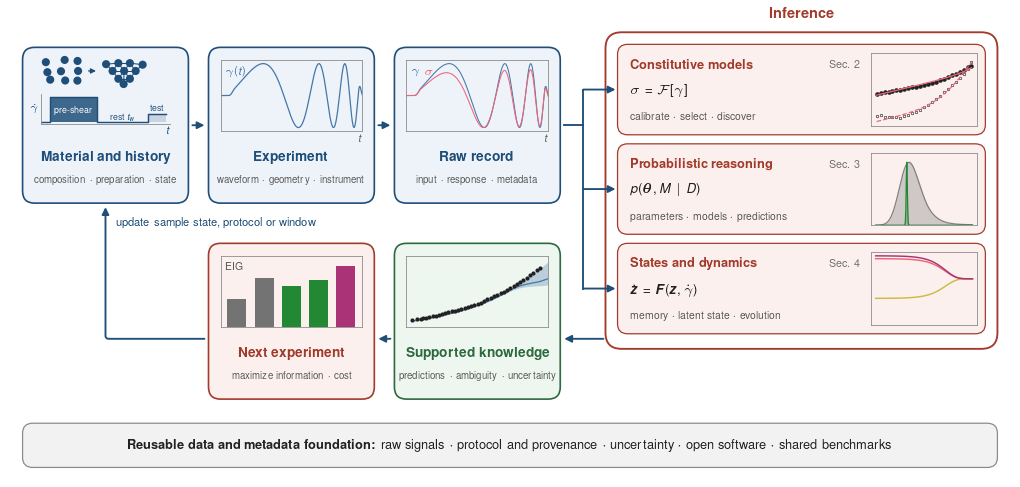

In [7]:
def make_fig1():
    use_style()
    m = F1_MINIS
    fig = plt.figure(figsize=(DOUBLE, DOUBLE * F1_H / F1_W))
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, F1_W); ax.set_ylim(0, F1_H); ax.axis("off")
    fs, ys = 16.5, 27.5                                # stage boxes: width, y

    # --- top row: material -> experiment -> raw record
    xs = [1.5, 20.0, 38.5]
    titles = [("Material and history", r"composition $\cdot$ preparation $\cdot$ state"),
              ("Experiment", r"waveform $\cdot$ geometry $\cdot$ instrument"),
              ("Raw record", r"input $\cdot$ response $\cdot$ metadata")]
    for x, (tt, sub) in zip(xs, titles):
        f1_box(ax, x, ys, fs, 15.5, NAVY, "#EEF3F9")
        f1_label(ax, x + fs / 2, ys + 4.6, tt, sub, color=NAVY)
    # material and history: preparation protocol (shear rate vs time) and the microstructure it produces
    x0m = xs[0] + 1.2; w_m = fs - 2.4
    hst = f1_mini(fig, ax, x0m + 0.6, ys + 7.9, w_m - 1.2, 3.0)
    tt = np.array([0, 0.6, 0.6, 3.8, 3.8, 7.2, 7.2, 8.4])
    gg = np.array([0, 0, 1, 1, 0, 0, 0.35, 0.35])
    hst.fill_between(tt, gg, step=None, color=NAVY, alpha=0.85, lw=0, where=(tt >= 0.6) & (tt <= 3.8))
    hst.fill_between(tt, gg, step=None, color=NAVY, alpha=0.18, lw=0, where=tt >= 7.2)
    hst.plot(tt, gg, color=NAVY, lw=0.7)
    hst.set_xlim(0, 8.7); hst.set_ylim(-0.05, 1.15)
    hst.text(2.2, 0.5, "pre-shear", ha="center", va="center", fontsize=4.3, color="white")
    hst.text(5.5, 0.26, r"rest $t_w$", ha="center", va="center", fontsize=4.3, color=NAVY)
    hst.text(7.8, 0.58, "test", ha="center", va="center", fontsize=4.3, color=NAVY)
    hst.text(-0.02, 0.5, r"$\dot\gamma$", transform=hst.transAxes, ha="right", va="center", fontsize=5, color=NAVY)
    hst.text(1.0, -0.06, r"$t$", transform=hst.transAxes, ha="right", va="top", fontsize=5, color=NAVY)
    hst.spines["top"].set_visible(False); hst.spines["right"].set_visible(False)

    # microstructure above the matching segments: broken up after pre-shear, rebuilt network after rest
    def to_x(tv):
        return x0m + 0.6 + tv / 8.7 * (w_m - 1.2)
    rng = np.random.default_rng(7)
    cy = ys + 13.15
    gx_, gy_ = np.meshgrid([-1.3, 0.0, 1.3], [-0.85, 0.0, 0.85])                                # dispersed
    Pd = np.c_[to_x(2.2) - 1.1 + gx_.ravel() + rng.uniform(-0.35, 0.35, 9), cy + gy_.ravel() + rng.uniform(-0.25, 0.25, 9)]
    for pt in Pd:
        ax.add_patch(Circle(pt, 0.3, color=NAVY))
    ang = np.linspace(0, 2 * np.pi, 7)[:-1]
    Pn = np.r_[np.c_[to_x(5.6) + 1.15 * np.cos(ang), cy + 0.9 * np.sin(ang)], [[to_x(5.6), cy]],
               np.c_[to_x(5.6) + 2.1 * np.cos(ang + 0.5), cy + 1.3 * np.sin(ang + 0.5)][[0, 2, 4]]]    # aggregated network
    for a_ in range(len(Pn)):
        for b_ in range(a_ + 1, len(Pn)):
            if np.hypot(*(Pn[a_] - Pn[b_])) < 1.55:
                ax.plot(*Pn[[a_, b_]].T, color=NAVY, lw=0.5)
    for pt in Pn:
        ax.add_patch(Circle(pt, 0.3, color=NAVY))
    f1_arrow(ax, (to_x(2.2) + 1.5, cy), (to_x(5.6) - 2.8, cy), lw=0.6, ms=5)
    # experiment: imposed chirp strain
    t, g, s = m["chirp"]
    e = f1_mini(fig, ax, xs[1] + 1.2, ys + 7.2, fs - 2.4, 7.0)
    e.plot(t, g, color=BLUE, lw=0.6); e.set_xlim(t[0], t[-1])
    e.text(0.03, 0.92, r"$\gamma(t)$", transform=e.transAxes, fontsize=5.5, va="top", color=BLUE)
    e.text(1.0, -0.04, r"$t$", transform=e.transAxes, fontsize=5, ha="right", va="top", color="0.35")
    # raw record: strain and stress
    r = f1_mini(fig, ax, xs[2] + 1.2, ys + 7.2, fs - 2.4, 7.0)
    r.plot(t, g / np.abs(g).max(), color=BLUE, lw=0.5)
    r.plot(t, s / np.abs(s).max(), color=RED, lw=0.5); r.set_xlim(t[0], t[-1])
    r.text(0.03, 0.92, r"$\gamma$", transform=r.transAxes, fontsize=5.5, va="top", color=BLUE)
    r.text(0.13, 0.92, r"$\sigma$", transform=r.transAxes, fontsize=5.5, va="top", color=RED)
    r.text(1.0, -0.04, r"$t$", transform=r.transAxes, fontsize=5, ha="right", va="top", color="0.35")
    for x0, x1 in ((xs[0] + fs, xs[1]), (xs[1] + fs, xs[2])):
        f1_arrow(ax, (x0 + 0.4, ys + 7.75), (x1 - 0.4, ys + 7.75))

    # --- inference group: three stacked boxes with miniatures
    gx, gy, gw, gh = 59.5, 13.0, 39.0, 31.5
    f1_box(ax, gx, gy, gw, gh, BRICK, "none", lw=0.9, r=1.6)
    ax.text(gx + gw / 2, gy + gh + 1.2, r"\textbf{Inference}", ha="center", va="bottom", fontsize=7, color=BRICK)
    rows = [("Constitutive models", r"$\sigma=\mathcal{F}[\gamma]$", r"calibrate $\cdot$ select $\cdot$ discover", "Sec. 2"),
            ("Probabilistic reasoning", r"$p(\boldsymbol\theta,M\mid D)$", r"parameters $\cdot$ models $\cdot$ predictions", "Sec. 3"),
            ("States and dynamics", r"$\dot{\boldsymbol z}=\boldsymbol F(\boldsymbol z,\dot\gamma)$", r"memory $\cdot$ latent state $\cdot$ evolution", "Sec. 4")]
    bh = 9.0
    for i, (tt, eq, sub, sec) in enumerate(rows):
        y = gy + gh - 1.2 - (i + 1) * bh - i * 0.9
        f1_box(ax, gx + 1.2, y, gw - 2.4, bh, BRICK, "#FBF0EE", lw=0.6, r=1.0)
        ax.text(gx + 2.4, y + bh - 2.0, rf"\textbf{{{tt}}}", fontsize=6.2, va="center", color=BRICK)
        ax.text(gx + 2.4, y + bh - 4.6, eq, fontsize=6.4, va="center", color=INK)
        ax.text(gx + 2.4, y + 1.8, sub, fontsize=5.0, va="center", color="0.35")
        ax.text(gx + gw - 13.6, y + bh - 2.0, sec, fontsize=5.2, va="center", ha="right", color="0.45")
        mm = f1_mini(fig, ax, gx + gw - 12.6, y + 0.9, 10.6, bh - 1.8)
        if i == 0:      # chia SAOS and fractional Kelvin-Voigt fit
            w, gp, gpp, wg, mp, mpp = m["saos"]
            mm.loglog(w, gp, "o", ms=1.2, color=INK); mm.loglog(w, gpp, "o", ms=1.2, mfc="white", mec=INK, mew=0.3)
            mm.loglog(wg, mp, color=RED, lw=0.6); mm.loglog(wg, mpp, color=RED, lw=0.6, ls="--")
            lo_, hi_ = min(gp.min(), gpp.min()), max(gp.max(), gpp.max())
            mm.set_ylim(lo_ / 1.6, hi_ * 1.6); mm.set_xlim(w.min() / 1.8, w.max() * 1.8)
        elif i == 1:    # eta0 posterior before and after creep
            a, b = m["eta"]; x = np.linspace(6.6, 8.2, 200)
            for v, col in ((a, "0.5"), (b, GREEN)):
                yk = gaussian_kde(v, 0.25)(x); yk /= yk.max()
                mm.fill_between(x, yk, color=col, alpha=0.35, lw=0); mm.plot(x, yk, color=col, lw=0.6)
            mm.set_ylim(0, 1.15)
        else:           # structure recovery after different rest times
            t, lam = m["lam"]
            for l_, col in zip(lam, (YELLOW, RED, PURPLE)):
                mm.semilogx(t[1:], l_[1:], color=col, lw=0.7)
            mm.set_ylim(0, 1.05)
        mm.minorticks_off(); mm.set_xticks([]); mm.set_yticks([])
    # raw record -> inference (branching)
    bx = xs[2] + fs
    ys_rows = [gy + gh - 1.2 - (i + 1) * bh - i * 0.9 + bh / 2 for i in range(3)]
    ax.plot([bx + 0.4, 57.3], [ys + 7.75, ys + 7.75], color=NAVY, lw=0.9)
    ax.plot([57.3, 57.3], [ys_rows[2], ys_rows[0]], color=NAVY, lw=0.9)
    for yr in ys_rows:
        f1_arrow(ax, (57.3, yr), (gx + 1.0, yr))

    # --- bottom row: next experiment <- supported knowledge
    kx, nx, by, bw = 38.5, 20.0, 8.0, 16.5
    f1_box(ax, kx, by, bw, 15.5, FOREST, "#EEF6F0")
    f1_label(ax, kx + bw / 2, by + 4.6, "Supported knowledge", r"predictions $\cdot$ ambiguity $\cdot$ uncertainty", color=FOREST)
    tc, Jc, tg, lo, med, hi = m["creep"]
    k = f1_mini(fig, ax, kx + 1.2, by + 7.2, bw - 2.4, 7.0)
    k.fill_between(tg, lo, hi, color=BLUE, alpha=0.3, lw=0); k.plot(tg, med, color=BLUE, lw=0.6)
    k.plot(tc, Jc, "o", ms=1.0, color=INK); k.set_xscale("log"); k.set_yscale("log")
    k.set_ylim(min(Jc.min(), lo.min()) / 1.6, max(Jc.max(), hi.max()) * 1.6); k.set_xlim(min(tg[0], tc.min()) / 1.6, tg[-1])
    k.minorticks_off(); k.set_xticks([]); k.set_yticks([])
    f1_box(ax, nx, by, bw, 15.5, BRICK, "#FBF0EE")
    f1_label(ax, nx + bw / 2, by + 4.6, "Next experiment", r"maximize information $\cdot$ cost", color=BRICK)
    n = f1_mini(fig, ax, nx + 1.2, by + 7.2, bw - 2.4, 7.0)
    vals = [v for _, _, v in m["eig"]]; kinds = [kd for _, kd, _ in m["eig"]]
    cols = {"saos": "0.45", "creep": GREEN, "relax": PURPLE}
    n.bar(range(len(vals)), vals, color=[cols[kd] for kd in kinds], width=0.7)
    n.set_xlim(-0.6, len(vals) - 0.4); n.set_ylim(0, max(vals) * 1.15)
    n.text(0.03, 0.92, "EIG", transform=n.transAxes, fontsize=5.0, va="top", color="0.35")
    # inference -> knowledge, knowledge -> next, next -> material (feedback)
    f1_arrow(ax, (gx - 0.2, by + 6.0), (kx + bw + 0.4, by + 6.0))
    f1_arrow(ax, (kx - 0.4, by + 6.0), (nx + bw + 0.4, by + 6.0))
    ax.add_patch(FancyArrowPatch((nx - 0.4, by + 6.0), (xs[0] + fs / 2, ys - 0.4), arrowstyle="-|>", mutation_scale=7,
                                 color=NAVY, lw=0.9, connectionstyle="angle,angleA=180,angleB=-90,rad=3",
                                 shrinkA=0, shrinkB=0))
    ax.text(xs[0] + fs / 2 + 1.0, (by + 15.5 + ys) / 2, r"update sample state, protocol or window",
            fontsize=5.4, color=NAVY, ha="left", va="center")

    # --- foundation bar
    f1_box(ax, 1.5, 1.2, 97.0, 4.4, "0.55", "#F2F2F2", lw=0.6, r=1.0)
    ax.text(50.0, 3.4, r"\textbf{Reusable data and metadata foundation:}\enspace raw signals $\cdot$ protocol and provenance "
                       r"$\cdot$ uncertainty $\cdot$ open software $\cdot$ shared benchmarks",
            ha="center", va="center", fontsize=6.2, color=INK)
    save(fig, "fig1_digital_loop", decades=False)
    return fig


show(make_fig1())

---
# Figure 2. Identifiability of a thixotropic model learned with RhINNs

**Question addressed.** A model that fits the data well does not necessarily have well-determined parameters. The example uses rheology-informed neural networks (RhINNs; Mahmoudabadbozchelou and Jamali, *Sci. Rep.* 2021) on synthetic data from a model with known parameters, so that the inferred parameters can be compared with the truth.

**Model.** The thixotropic structural kinetics defined in *Shared models*. Because $\lambda_{ss}=1/(1+(k_-/k_+)\dot\gamma)$, a flow curve contains only $\sigma_y$, $\eta_\infty$ and the ratio $k_-/k_+$; the kinetic time scale set by $k_+$ can only be seen in transient data.

**Synthetic data.** Generated from the true parameters with 2 % multiplicative noise on the stress:
- dataset A: a steady flow curve at 15 shear rates between $10^{-2}$ and $10^{2}$ s⁻¹;
- dataset B: dataset A plus two step-rate transients over 60 s ($10\to0.1$ and $0.1\to10$ s⁻¹, starting from the steady structure of the first rate).

In [8]:
import torch

torch.set_default_dtype(torch.float64)
RHINN_DIR = os.path.join(RESULTS, "rhinn")
NOISE_RHINN = 0.02                             # relative noise on stress
FLOW_RATES = np.logspace(-2, 2, 15)            # s^-1
STEPS = [(10.0, 0.1), (0.1, 10.0)]             # (pre-shear rate, step rate), s^-1
T_STEP = 60.0                                  # s, duration of each transient
N_STEP = 40                                    # samples per transient (log-spaced)


def make_rhinn_data(seed=0):
    rng = np.random.default_rng(seed)
    p = TRUTH
    flow = dict(gdot=FLOW_RATES,
                sigma=(p["sigma_y"] * lam_ss(FLOW_RATES, p) + p["eta_inf"] * FLOW_RATES)
                * np.exp(NOISE_RHINN * rng.standard_normal(FLOW_RATES.size)))
    steps = []
    for g1, g2 in STEPS:
        t = np.r_[0.0, np.logspace(-1, np.log10(T_STEP), N_STEP - 1)]
        lam, sig = simulate(lambda tt: g2, t, lam_ss(g1, p), p)
        steps.append(dict(g1=g1, g2=g2, t=t, lam=lam, sigma=sig * np.exp(NOISE_RHINN * rng.standard_normal(t.size))))
    return flow, steps

**RhINN.** A small fully connected network (3 hidden layers of 32 tanh units, sigmoid output) represents $\lambda$ for each experiment: one network maps $\log_{10}\dot\gamma$ to $\lambda_{ss}$ for the flow curve, and one network per transient maps time to $\lambda(t)$. The four model parameters are trainable (in log space) and shared by all networks. The loss has two parts:

- **data loss**: squared error of $\log\sigma$ predicted by the constitutive equation against the measured $\log\sigma$;
- **physics loss** (weight 10): the steady-state structure equation on 80 collocation rates; for each transient, the kinetic ODE residual on 121 collocation times (the derivative $d\lambda/dt$ comes from automatic differentiation) and the initial condition $\lambda(0)=\lambda_{ss}(\dot\gamma_1)$.

Adam is used with separate learning rates for the networks ($2\times10^{-3}$) and the physical parameters ($2\times10^{-2}$), 8000 iterations, step decay ×0.3 every third of the run. Each RhINN starts from random initial parameters drawn over two decades, and twenty independently initialized RhINNs are trained on dataset A and twenty on dataset B (random seeds 1000–1019). Training all forty takes about 10 min on a laptop CPU; the results are stored in `results/rhinn/`.

In [9]:
class MLP(torch.nn.Module):
    def __init__(self, width=32, depth=3):
        super().__init__()
        layers, d = [], 1
        for _ in range(depth):
            layers += [torch.nn.Linear(d, width), torch.nn.Tanh()]
            d = width
        layers += [torch.nn.Linear(d, 1)]
        self.net = torch.nn.Sequential(*layers)

    def forward(self, x):
        return torch.sigmoid(self.net(x))          # lambda in (0, 1)


class RhINN(torch.nn.Module):
    """One lambda-network per experiment; shared constitutive parameters."""

    def __init__(self, n_steps, init):
        super().__init__()
        self.log_p = torch.nn.ParameterDict({k: torch.nn.Parameter(torch.tensor(np.log(v))) for k, v in init.items()})
        self.flow_net = MLP()                      # lambda_ss(log10 gdot)
        self.step_nets = torch.nn.ModuleList([MLP() for _ in range(n_steps)])

    def p(self, k):
        return torch.exp(self.log_p[k])


def train_rhinn(flow, steps, use_steps, seed, n_iter=8000, lr=2e-3, lr_phys=2e-2, w_phys=10.0):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    # random initial guesses over two decades around plausible magnitudes
    init = dict(sigma_y=10 ** rng.uniform(0, 2), eta_inf=10 ** rng.uniform(-2, 0),
                k_plus=10 ** rng.uniform(-2.5, 0.5), k_minus=10 ** rng.uniform(-2.5, 0.5))
    model = RhINN(len(steps) if use_steps else 0, init)
    nets = [q for n, q in model.named_parameters() if not n.startswith("log_p")]
    opt = torch.optim.Adam([dict(params=nets, lr=lr), dict(params=list(model.log_p.values()), lr=lr_phys)])
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=n_iter // 3, gamma=0.3)

    xg = torch.tensor(np.log10(flow["gdot"]))[:, None]
    gd = torch.tensor(flow["gdot"])[:, None]
    ls_f = torch.tensor(np.log(flow["sigma"]))[:, None]
    xg_col = torch.linspace(-2.5, 2.5, 80)[:, None]          # collocation rates (log10)
    st = [dict(tn=torch.tensor(s["t"] / T_STEP)[:, None], ls=torch.tensor(np.log(s["sigma"]))[:, None],
               g1=s["g1"], g2=s["g2"]) for s in (steps if use_steps else [])]
    t_col = torch.cat([torch.zeros(1), torch.logspace(-3, 0, 120)])[:, None]   # collocation times (t / T_STEP)

    hist = []
    for it in range(n_iter):
        opt.zero_grad()
        sy, eta, kp, km = (model.p(k) for k in ("sigma_y", "eta_inf", "k_plus", "k_minus"))
        # steady flow curve: data + algebraic (steady-state) structure residual
        lam_f = model.flow_net(xg)
        loss_data = torch.mean((torch.log(sy * lam_f + eta * gd) - ls_f) ** 2)
        lam_c = model.flow_net(xg_col)
        gc = 10 ** xg_col
        rho = km / kp
        loss_phys = torch.mean((((1 - lam_c) - rho * lam_c * gc) / (1 + rho.detach() * gc)) ** 2)
        # transients: data + ODE residual (autograd) + initial condition at steady state
        for k, s in enumerate(st):
            net = model.step_nets[k]
            lam_d = net(s["tn"])
            loss_data = loss_data + torch.mean((torch.log(sy * lam_d + eta * s["g2"]) - s["ls"]) ** 2)
            tc = t_col.clone().requires_grad_(True)
            lam = net(tc)
            dlam = torch.autograd.grad(lam.sum(), tc, create_graph=True)[0] / T_STEP
            res = (dlam - (kp * (1 - lam) - km * lam * s["g2"])) / (kp + km * s["g2"]).detach()
            lam0 = net(torch.zeros(1, 1))
            loss_phys = loss_phys + torch.mean(res ** 2) + (lam0 - 1 / (1 + km / kp * s["g1"])).pow(2).sum()
        loss = loss_data + w_phys * loss_phys
        loss.backward()
        opt.step(); sched.step()
        if it % 200 == 0 or it == n_iter - 1:
            hist.append((it, float(loss_data.detach()), float(loss_phys.detach())))
    return dict(seed=seed, init=init, params={k: float(model.p(k)) for k in init}, history=hist)


def rhinn_ensembles(n_members=20, n_iter=8000):
    """Twenty RhINNs on dataset A ("steady") and twenty on dataset B ("steady_transient"); cached."""
    os.makedirs(RHINN_DIR, exist_ok=True)
    flow, steps = make_rhinn_data()
    data_file = os.path.join(RHINN_DIR, "data.json")
    if not os.path.exists(data_file):
        json.dump(dict(truth=TRUTH, noise=NOISE_RHINN, flow={k: v.tolist() for k, v in flow.items()},
                       steps=[{k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in s.items()} for s in steps]),
                  open(data_file, "w"))
    ens = {}
    for name, use in (("steady", False), ("steady_transient", True)):
        fn = os.path.join(RHINN_DIR, f"ensemble_{name}.json")
        if not os.path.exists(fn):
            members = [train_rhinn(flow, steps, use, seed=1000 + m, n_iter=n_iter) for m in range(n_members)]
            json.dump(dict(members=members), open(fn, "w"))
        ens[name] = json.load(open(fn))["members"]
    return json.load(open(data_file)), ens


RHINN_DATA, RHINN_ENS = rhinn_ensembles()
for name, members in RHINN_ENS.items():
    P = np.array([[m["params"][k] for k in ("sigma_y", "eta_inf", "k_plus", "k_minus")] for m in members])
    print(f"{name:17s} k_+ range {P[:, 2].min():.3g}-{P[:, 2].max():.3g} s^-1, "
          f"k_-/k_+ = {np.median(P[:, 3] / P[:, 2]):.3f} (true {TRUTH['k_minus'] / TRUTH['k_plus']:.3f})")

steady            k_+ range 0.0123-3.13 s^-1, k_-/k_+ = 0.510 (true 0.500)
steady_transient  k_+ range 0.0991-0.0997 s^-1, k_-/k_+ = 0.502 (true 0.500)


**Figure panels.** Each trained RhINN is turned back into a model by inserting its learned parameters into the exact equations above, which are then integrated with SciPy:

- **(a)** flow curves of all forty RhINNs against the data and the true model; both ensembles fit;
- **(b)** the step transients (dataset B): fitted by the blue ensemble, predicted by the red ensemble that never saw them;
- **(c)** the learned $(k_+,k_-)$: the red ensemble spreads along the ridge $k_-/k_+=\text{const}$ fixed by the flow curve, the blue ensemble collapses onto the true point;
- **(d)** prediction of an unseen protocol, a shear-rate ramp up and down starting from rest (inset), which separates the two ensembles.

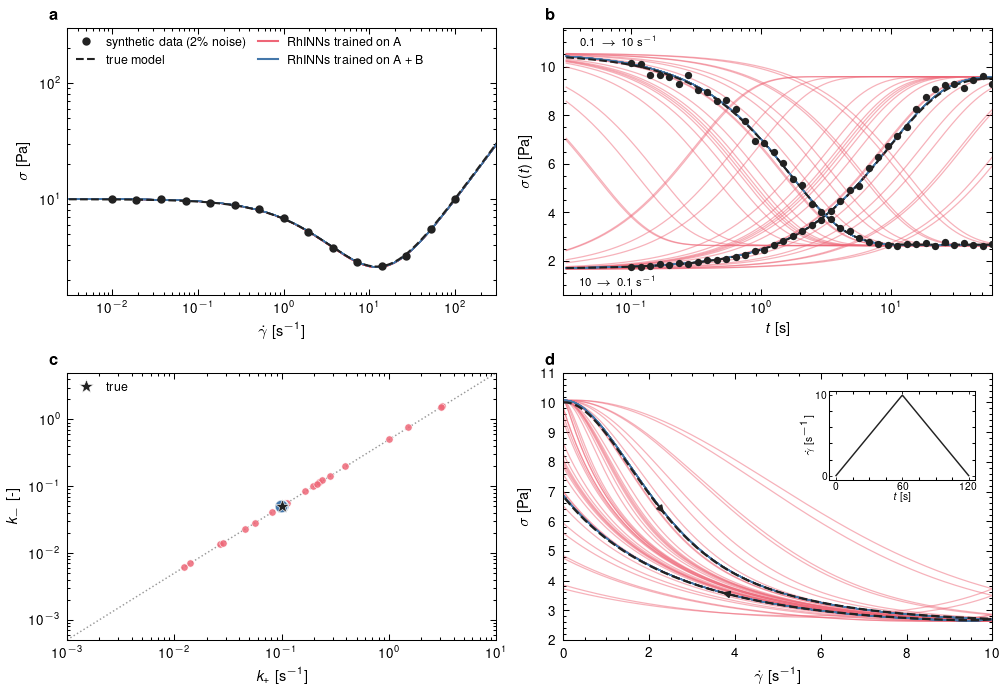

In [10]:
def loop_response(p, T=120.0, n=400):
    t = np.linspace(0, T, n)
    g = loop_protocol(T)
    lam, sig = simulate(g, t, 1.0, p)          # start from rest (fully built structure)
    return t, np.array([g(x) for x in t]), sig


def make_fig2():
    use_style()
    d, ens = RHINN_DATA, RHINN_ENS
    truth = d["truth"]
    fig, axs = plt.subplots(2, 2, figsize=(DOUBLE, 4.6), constrained_layout=True)
    a, b, c, e = axs.ravel()

    # (a) model and training data A: the steady flow curve
    gg = np.logspace(-2.5, 2.5, 200)
    for k, col in (("steady", RED), ("steady_transient", BLUE)):
        for m in ens[k]:
            p = m["params"]
            a.plot(gg, p["sigma_y"] * lam_ss(gg, p) + p["eta_inf"] * gg, color=col, lw=0.6, alpha=0.5)
    a.plot(gg, truth["sigma_y"] * lam_ss(gg, truth) + truth["eta_inf"] * gg, color=INK, lw=1.0, ls="--")
    a.plot(d["flow"]["gdot"], d["flow"]["sigma"], "o", color=INK, ms=3, zorder=5)
    a.plot([], [], "o", color=INK, ms=3, label="synthetic data (2\\% noise)")
    a.plot([], [], color=INK, lw=1.0, ls="--", label="true model")
    a.plot([], [], color=RED, label="RhINNs trained on A")
    a.plot([], [], color=BLUE, label="RhINNs trained on A + B")
    a.set(xscale="log", yscale="log", xlabel=r"$\dot\gamma$ [s$^{-1}$]", ylabel=r"$\sigma$ [Pa]",
          xlim=(3e-3, 3e2), ylim=(1.5, 300))
    a.legend(loc="upper left", ncol=2, columnspacing=1.0)
    panel(a, "a")

    # (b) training data B: step-rate transients, fitted (blue) and predicted by the flow-curve RhINNs (red)
    tg = np.r_[0.0, np.logspace(-1.5, np.log10(T_STEP), 200)]
    for s in d["steps"]:
        for k, col in (("steady", RED), ("steady_transient", BLUE)):
            for m in ens[k]:
                p = m["params"]
                _, sig = simulate(lambda t, g=s["g2"]: g, tg, lam_ss(s["g1"], p), p)
                b.plot(tg[1:], sig[1:], color=col, lw=0.6, alpha=0.5)
        _, sig = simulate(lambda t, g=s["g2"]: g, tg, lam_ss(s["g1"], truth), truth)
        b.plot(tg[1:], sig[1:], color=INK, lw=1.0, ls="--")
        b.plot(np.asarray(s["t"])[1:], np.asarray(s["sigma"])[1:], "o", color=INK, ms=2.5, zorder=5)
    b.text(0.04, 10.75, r"$0.1\to10$ s$^{-1}$", fontsize=5.5, ha="left", va="bottom")
    b.text(0.04, 0.85, r"$10\to0.1$ s$^{-1}$", fontsize=5.5, ha="left", va="bottom")
    b.set(xscale="log", xlabel=r"$t$ [s]", ylabel=r"$\sigma(t)$ [Pa]", xlim=(0.03, 60), ylim=(0.6, 11.6))
    panel(b, "b")

    # (c) parameter plane
    kp = np.logspace(-3, 1, 50)
    c.plot(kp, kp * truth["k_minus"] / truth["k_plus"], color="0.6", lw=0.7, ls=":")
    for k, col, ms in (("steady", RED, 3.5), ("steady_transient", BLUE, 6)):
        P = np.array([[m["params"]["k_plus"], m["params"]["k_minus"]] for m in ens[k]])
        c.plot(P[:, 0], P[:, 1], "o", color=col, ms=ms, alpha=0.85, mec="white", mew=0.3, zorder=3 if ms < 5 else 4)
    c.plot(truth["k_plus"], truth["k_minus"], "*", color=INK, ms=7, mec="white", mew=0.3, zorder=5, label="true")
    c.set(xscale="log", yscale="log", xlim=(1e-3, 10), ylim=(5e-4, 5), xlabel=r"$k_+$ [s$^{-1}$]", ylabel=r"$k_-$ [-]")
    c.legend(loc="upper left")
    panel(c, "c")

    # (d) prediction of an unseen protocol: shear-rate ramp up and down from rest
    for k, col in (("steady", RED), ("steady_transient", BLUE)):
        for m in ens[k]:
            t, g, sig = loop_response(m["params"])
            e.plot(g, sig, color=col, lw=0.6, alpha=0.5)
    t, g, sig = loop_response(truth)
    e.plot(g, sig, color=INK, lw=1.1, ls="--")
    up = np.argmin(np.abs(g[: len(g) // 2] - 2.0)); dn = len(g) // 2 + np.argmin(np.abs(g[len(g) // 2:] - 4.0))
    e.annotate("", xy=(g[up + 8], sig[up + 8]), xytext=(g[up], sig[up]), arrowprops=dict(arrowstyle="-|>", color=INK, lw=0.8))
    e.annotate("", xy=(g[dn + 8], sig[dn + 8]), xytext=(g[dn], sig[dn]), arrowprops=dict(arrowstyle="-|>", color=INK, lw=0.8))
    e.set(xlabel=r"$\dot\gamma$ [s$^{-1}$]", ylabel=r"$\sigma$ [Pa]", xlim=(0, 10), ylim=(2, 11))
    ins = e.inset_axes([0.62, 0.6, 0.34, 0.33])
    tt = np.linspace(0, 120, 200); gp = loop_protocol(120.0)
    ins.plot(tt, [gp(x) for x in tt], color=INK, lw=0.7)
    ins.set_xlabel(r"$t$ [s]", fontsize=5, labelpad=0.5); ins.set_ylabel(r"$\dot\gamma$ [s$^{-1}$]", fontsize=5, labelpad=0.5)
    ins.tick_params(labelsize=5, length=1.5, width=0.4, pad=1); ins.set(xticks=(0, 60, 120), yticks=(0, 10))
    panel(e, "d")
    save(fig, "fig_rhinn_identifiability_4panel")
    return fig


show(make_fig2())

---
# Figure 3. Gaussian processes in rheology

Three uses of Gaussian processes (GPs) on measured data, one per panel.

## (a) GP superposition of polystyrene $|G^*(\omega)|$

The automated superposition method of Lennon, McKinley and Swan (package `mastercurves`) fits one GP to $\ln|G^*|$ versus $\ln\omega$ at each temperature, then finds the horizontal shift $a_T$ and vertical shift $b_T$ that maximize the likelihood of each shifted data set under the GPs of its neighbors. The shift factors therefore come with uncertainties. The reference temperature is 160 °C. The panel shows the unshifted data and their GPs (faded), the shifted data forming the master curve, and in the inset $a_T(T)$ with its 95 % intervals and a WLF fit $\log_{10}a_T=-C_1(T-T_{\rm ref})/(C_2+T-T_{\rm ref})$.

In [11]:
from scipy.optimize import curve_fit
from mastercurves import MasterCurve
from mastercurves.transforms import Multiply

T_REF = 160
TCOL = dict(zip(TEMPS, plt.cm.tab10.colors))   # high-contrast temperature colors
INSET_FS = 5.0


def gstar_mastercurve():
    """Lennon-McKinley-Swan GP superposition applied directly to |G*|(omega)."""
    x = [np.log(PS_SAOS[T]["w"]) for T in TEMPS]
    y = [np.log(np.hypot(PS_SAOS[T]["Gp"], PS_SAOS[T]["Gpp"])) for T in TEMPS]
    mc = MasterCurve()
    mc.add_data(x, y, TEMPS)
    mc.add_htransform(Multiply())
    mc.add_vtransform(Multiply())
    mc.superpose()
    mc.change_ref(T_REF)
    return mc, x, y


def inset_style(ax):
    ax.tick_params(labelsize=INSET_FS, length=1.6, width=0.4, pad=1.2)
    ax.tick_params(which="minor", length=0.9, width=0.3)
    ax.xaxis.label.set_size(INSET_FS); ax.yaxis.label.set_size(INSET_FS)
    ax.xaxis.labelpad = 0.5; ax.yaxis.labelpad = 0.5
    for sp in ax.spines.values():
        sp.set_linewidth(0.4)


def panel_master(a, letter="a"):
    from matplotlib.ticker import LogLocator, LogFormatterSciNotation, NullFormatter
    mc, x, y = gstar_mastercurve()
    aT = np.array(mc.hparams[0], float); daT = np.array(mc.huncertainties[0], float)
    bT = np.array(mc.vparams[0], float)
    for k, T in enumerate(TEMPS):
        gp = mc.gps[k]
        xg = np.linspace(x[k].min() - 1, x[k].max() + 1, 120)
        m, sd = gp.predict(xg[:, None], return_std=True)
        W, F = np.exp(xg), bT[k]
        a.plot(np.exp(x[k]), np.exp(y[k]), "o", color=TCOL[T], ms=3.0, alpha=0.25, mew=0)           # unshifted data
        a.plot(W, np.exp(m), color=TCOL[T], lw=0.35, alpha=1)                                          # its GP
        a.fill_between(W, F * np.exp(m - 2 * sd), F * np.exp(m + 2 * sd), color=TCOL[T], alpha=0.25, lw=0)
        a.plot(W * aT[k], F * np.exp(m), color=TCOL[T], lw=0.0)
        a.plot(np.exp(x[k]) * aT[k], F * np.exp(y[k]), "o", color=TCOL[T], ms=3.0, mew=0, label=rf"{T}\,$^\circ$C")
    a.set(xscale="log", yscale="log", xlim=(2e-4, 3e5), ylim=(3e2, 3e8),
          xlabel=r"$a_T\,\omega$ [rad\,s$^{-1}$]", ylabel=r"$b_T\,|G^*(a_T\omega)|$ [Pa]")
    a.xaxis.set_major_locator(LogLocator(base=100, numticks=20))
    a.xaxis.set_major_formatter(LogFormatterSciNotation(base=10))
    a.xaxis.set_minor_locator(LogLocator(base=10, subs=(1.0,), numticks=20)); a.xaxis.set_minor_formatter(NullFormatter())
    a.yaxis.set_major_locator(LogLocator(base=10, numticks=20))
    a.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10), numticks=20)); a.yaxis.set_minor_formatter(NullFormatter())
    a.keep_ticks = True
    a.plot([], [], color="0.35", lw=0.8, label=r"$|\bar{G}^*|$")
    a.legend(loc="lower right", handletextpad=0.35, borderaxespad=0.2, labelspacing=0.2, markerscale=1.3)
    panel(a, letter)
    # inset: shift factors with WLF fit
    ins = a.inset_axes([0.15, 0.645, 0.32, 0.32])
    wlf = lambda T, C1, C2: -C1 * (T - T_REF) / (C2 + T - T_REF)
    (C1, C2), _ = curve_fit(wlf, np.array(TEMPS, float), np.log10(aT), p0=(6, 120))
    Tg = np.linspace(125, 195, 100)
    ins.plot(Tg, 10 ** wlf(Tg, C1, C2), color=INK, lw=0.6)
    for T, v, dv in zip(TEMPS, aT, daT):
        ins.errorbar(T, v, yerr=2 * dv, fmt="o", color=TCOL[T], ms=2.2, elinewidth=0.5, capsize=0.8)
    ins.set(yscale="log", xlabel=r"$T$ [$^\circ$C]", ylabel=r"$a_T$ [-]", xticks=(140, 170))
    ins.text(0.95, 0.92, "WLF", transform=ins.transAxes, ha="right", va="top", fontsize=INSET_FS)
    inset_style(ins)
    print(f"WLF at T_ref = {T_REF} C: C1 = {C1:.2f}, C2 = {C2:.1f} K")

## (b) RheoGP: linear memory from one raw chirp (wormlike micelles)

RheoGP (public package `rheogp` v1.1.0) is a physics-informed sparse variational GP that maps the raw strain signal $\gamma(t)$ to the raw stress $\sigma(t)$ through a causal Boltzmann convolution with a memory kernel. Here the kernel is constrained to a fractional Maxwell liquid (FML). The model is trained on the 3 s chirp in `data/micelles` and then predicts, without retraining, the two 15 s chirps; those predictions are used in Figure 4. Training settings: linear GP kernel, causal convolution, exact quadrature, 300 inducing points, learning rate 0.005, $\omega\in[10^{-3},10^{3}]$ rad/s, 20 000 epochs, seed 42 (about 1 min on a laptop CPU). The run is deterministic. With 2 inducing points the fit takes about 30 s and the inferred moduli change by less than 0.05 %, but the fraction of offset-corrected residuals inside the 95 % band in Figure 4 drops from 100 % to 98 %.

The top plot shows the training chirp with the posterior mean $\bar\sigma(t)$. The bottom plot compares the $G'(\omega)$ and $G''(\omega)$ implied by the inferred memory with the moduli obtained directly from the same chirp by a discrete Fourier transform, $G^*=\mathcal F[\sigma]/\mathcal F[\gamma]$, at the frequencies the chirp excites (shaded).

In [12]:
import rheogp

RHEOGP_DIR = os.path.join(RESULTS, "rheogp", "FML")
RHEOGP_TRAIN = "micelles_chirps_short_0"                  # 3 s training chirp
RHEOGP_TESTS = ["micelles_chirp_-90", "micelles_chirp_90"]  # 15 s chirps, never used in training
RHEOGP_KW = dict(kernel="linear", convolution="causal", quadrature="exact", inducing_points=300,
                 learning_rate=0.005, learning_rate_physics=0.005, omega_min=1e-3, omega_max=1e3,
                 n_epochs=20000, seed=42, verbose=False)


def train_rheogp():
    """Trains the FML-kernel RheoGP on the short chirp and predicts the two long chirps (cached)."""
    if os.path.exists(os.path.join(RHEOGP_DIR, "predictions.npz")):
        return
    import torch
    previous = torch.get_default_dtype()
    torch.set_default_dtype(torch.float32)          # RheoGP runs in single precision (the RhINN cell sets float64)
    try:
        t, g, s = read_chirp(RHEOGP_TRAIN)
        m = rheogp.SPGP(model="FML", **RHEOGP_KW).fit(t.astype(np.float32), g.astype(np.float32), s.astype(np.float32))
        m.results().save(os.path.join(RHEOGP_DIR, "train"))
        arrs = {}
        for name in RHEOGP_TESTS:
            t2, g2, s2 = read_chirp(name)
            mu, sd = m.predict(g2.astype(np.float32), time=t2.astype(np.float32), return_std=True)
            arrs.update({f"{name}__t": t2, f"{name}__strain": g2, f"{name}__stress": s2,
                         f"{name}__mu": np.asarray(mu, float), f"{name}__sd": np.asarray(sd, float)})
        np.savez(os.path.join(RHEOGP_DIR, "predictions.npz"), **arrs)
    finally:
        torch.set_default_dtype(previous)


train_rheogp()
RHEOGP_RES = rheogp.FitResult.load(os.path.join(RHEOGP_DIR, "train"))


def train_dft(res):
    """G* = FFT(stress)/FFT(strain) of the training chirp, at the excited frequencies."""
    dt = float(np.mean(np.diff(res.t)))
    w = 2 * np.pi * np.fft.rfftfreq(len(res.t), d=dt)
    Fg, Fs = np.fft.rfft(res.strain), np.fft.rfft(res.target)
    k = (w > 0) & (np.abs(Fg) > 0.1 * np.abs(Fg).max())
    G = Fs[k] / Fg[k]
    return w[k], G.real, G.imag


def panel_chirp(b, b2, letter="b"):
    res = RHEOGP_RES
    b.plot(res.t, res.target, ".", color=BLUE, ms=3)
    b.plot(res.t, res.prediction, "--", color=INK, lw=0.7, label=r"$\bar{\sigma}(t)$")
    b.set(xlabel=r"$t$ [s]", ylabel=r"$\sigma(t)$ [Pa]", xlim=(0, res.t.max()), ylim=(-6.8, 6.5))
    b.legend(loc="lower left", markerscale=3, borderaxespad=0.2)
    panel(b, letter)
    m = res.omega > 0
    w, Gp, Gdp = res.omega[m], res.Gp[m], res.Gdp[m]
    wd, Gpd, Gdpd = train_dft(res)
    b2.axvspan(wd.min(), wd.max(), color=GREY, alpha=0.18, lw=0)
    b2.plot(w, Gp, color="k", lw=0.7, label=r"$\bar{G}^{\prime}$")
    b2.plot(w, Gdp, color="k", lw=0.7, ls="--", label=r"$\bar{G}^{\prime\prime}$")
    b2.plot(wd, Gpd, "o", mfc=BLUE, mec=BLUE, mew=0.5, ms=3)
    b2.plot(wd, Gdpd, "o", mfc="white", mec=BLUE, mew=0.5, ms=3)
    b2.set(xscale="log", yscale="log", xlim=(1e-1, 1e3), ylim=(0.3, 300),
           xlabel=r"$\omega$ [rad\,s$^{-1}$]", ylabel=r"$G^{\prime}$, $G^{\prime\prime}$ [Pa]")
    b2.text(np.sqrt(wd.min() * wd.max()), 0.4, "DFT", color="0.3", fontsize=INSET_FS, ha="center", va="bottom")
    b2.legend(loc="upper left", borderaxespad=0.3, labelspacing=0.2)

## (c) Amplitude-aware Fourier GP on a LAOS sweep (cellulose nanofibrils, 1 wt%)

All stress waveforms of the amplitude sweep in `data/cnf_laos_1.0wt` (21 amplitudes, $\omega=1$ rad/s) are modeled jointly; the method is that of the `laosgp` package, implemented here in full with numpy and torch.

1. **Preprocessing** of each record: drop the start-up transient ($t<0.25$ s); estimate the strain amplitude $\gamma_0$ from the RMS strain and the phase from the strain zero crossings, so that $\gamma=\gamma_0\sin\omega\tau$; remove isolated stress outliers (second-difference peaks above 6 robust standard deviations); subtract the whole-cycle mean stress; average into 100 bins; estimate the noise level of a bin from second differences.
2. **Model.** With the aligned strain, $\sigma(t)=\gamma_0\sum_{n=1,3}[G_n'(\gamma_0)\sin n\omega t+G_n''(\gamma_0)\cos n\omega t]+\varepsilon$, and each Fourier modulus is a GP over $x=\log_{10}\gamma_0$ with a sigmoid prior mean (low and high plateaus; the low plateau of the third harmonic fixed at zero) and a Matérn-5/2 covariance. The stress is then one GP with kernel $\sum_f v_f\,\phi_f\phi_f'\,k_{5/2}(x,x';\ell_f)$, a sum over the four Fourier features of a linear kernel times a Matérn-5/2 kernel. Each record has its own noise scale.
3. **Fit.** All hyperparameters maximize the exact log marginal likelihood (Cholesky; Adam, learning rate 0.05, 300 iterations). The procedure is deterministic. One amplitude, $\gamma_0=0.631$, is withheld and predicted from the others.
4. **Baseline.** Per-record least-squares Fourier moduli of every record, including the withheld one.

The panel shows the GP first-harmonic moduli $\bar G_1'(\gamma_0)$, $\bar G_1''(\gamma_0)$ with 95 % bands, the per-record least-squares values (blue circles; withheld amplitude as black squares) and, in the inset, normalized Lissajous curves at three amplitudes (dots: measured; lines: GP; dashed: withheld amplitude). The fit takes 2–3 min and is stored in `results/laos/laos_matern52.pkl`. It reproduces the current `laosgp` package to a relative precision of about $10^{-7}$.

WLF at T_ref = 160 C: C1 = 6.04, C2 = 103.8 K


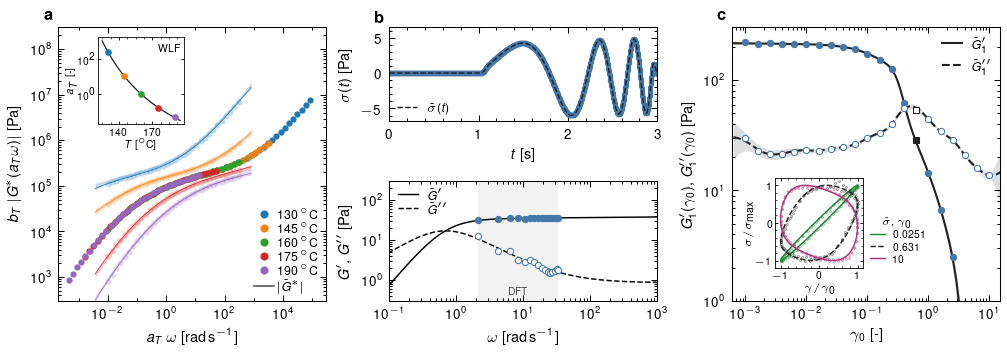

In [13]:
import glob
import math
import re

LAOS_DIR = os.path.join(DATA_DIR, "cnf_laos_1.0wt")
LAOS_CACHE = os.path.join(RESULTS, "laos", "laos_matern52.pkl")
HARMONICS = (1, 3)        # odd harmonics modeled
F = 2 * len(HARMONICS)    # features [G'_1, G''_1, G'_3, G''_3]
OMEGA = 1.0               # angular frequency of the sweep [rad/s]
DT = torch.float64



# ----------------------------------------------------------------------------- data
def load_sweep(folder):
    """One CSV per amplitude ('..._amp_<gamma0>.csv'; columns Time, Shear Strain, Shear Stress).
    Returns records sorted by nominal amplitude gamma0 (parsed from the file name)."""
    recs = []
    for f in sorted(glob.glob(os.path.join(folder, "*amp_*.csv"))):
        df = pd.read_csv(f)
        t, g, s = (df[c].values.astype(float) for c in ("Time", "Shear Strain", "Shear Stress"))
        ok = np.isfinite(t) & np.isfinite(g) & np.isfinite(s)
        o = np.argsort(t[ok])
        g0 = float(re.search(r"amp_([0-9]*\.?[0-9]+)", os.path.basename(f)).group(1))
        recs.append(dict(time=t[ok][o], strain=g[ok][o], stress=s[ok][o], gamma0=g0))
    return sorted(recs, key=lambda r: r["gamma0"])


# ---------------------------------------------------------------------- preprocessing
def _last_whole_cycles(t):
    """Mask of the largest whole number of cycles at the end of the record."""
    P = 2 * np.pi / OMEGA
    k = int(np.floor((t[-1] - t[0]) / P))
    return t >= t[-1] - k * P if k >= 1 else np.ones_like(t, bool)


def _cycle_mean(t, y):
    sel = _last_whole_cycles(t)
    return float(np.trapezoid(y[sel], t[sel]) / (t[sel][-1] - t[sel][0]))


def _diff_noise_std(y):
    """Robust noise std of one sample from second differences: 1.4826 MAD(d2) / sqrt(6)."""
    d2 = y[2:] - 2 * y[1:-1] + y[:-2]
    return float(1.4826 * np.median(np.abs(d2 - np.median(d2))) / np.sqrt(6.0)), d2


def preprocess(rec, t_cut=0.25, clip_sigma=6.0, n_points=100):
    """Clean one record, without any regression on the stress:
    (i) drop the start-up transient t < t_cut; (ii) strain amplitude from the RMS strain and
    phase from its zero crossings, giving the aligned time tau with gamma = gamma0 sin(omega tau);
    (iii) remove isolated outliers (peaks of the stress second difference above clip_sigma
    robust standard deviations, iterated); (iv) subtract the whole-cycle mean stress;
    (v) bin-average to n_points; (vi) initial noise level of a binned point."""
    t = rec["time"] - rec["time"][0]
    keep = t >= t_cut
    t, gam, sig = t[keep], rec["strain"][keep], rec["stress"][keep]

    # (ii) amplitude = sqrt(2) RMS of the strain about its whole-cycle mean
    sel = _last_whole_cycles(t)
    ts, gs = t[sel], gam[sel]
    c = np.trapezoid(gs, ts) / (ts[-1] - ts[0])
    g0 = float(np.sqrt(2 * np.trapezoid((gs - c) ** 2, ts) / (ts[-1] - ts[0])))
    # phase delta of gamma0 sin(omega t + delta): circular mean over all zero crossings
    y = gam - c
    i = np.where(np.sign(y[:-1]) * np.sign(y[1:]) < 0)[0]
    tc = t[i] - y[i] * (t[i + 1] - t[i]) / (y[i + 1] - y[i])
    ang = np.where(y[i + 1] > y[i], -OMEGA * tc, np.pi - OMEGA * tc)
    delta = float(np.angle(np.mean(np.exp(1j * ang))))
    tau = t + delta / OMEGA

    # (iii) outliers
    mask = np.ones(len(tau), bool)
    for _ in range(3):
        idx = np.where(mask)[0]
        s, d2 = _diff_noise_std(sig[idx])
        a = np.abs(d2 - np.median(d2))
        peak = (a > clip_sigma * np.sqrt(6.0) * max(s, 1e-300)) & (a >= np.r_[0, a[:-1]]) & (a >= np.r_[a[1:], 0])
        bad = idx[1:-1][peak]
        if len(bad) == 0:
            break
        mask[bad] = False
    tau, sig = tau[mask], sig[mask]
    noise_raw, _ = _diff_noise_std(sig)
    # (iv) offset
    sig = sig - _cycle_mean(tau, sig)
    # (v) bin averaging
    edges = np.linspace(0, len(tau), n_points + 1).astype(int)
    counts = np.diff(edges)
    tau = np.add.reduceat(tau, edges[:-1]) / counts
    sig = np.add.reduceat(sig, edges[:-1]) / counts
    # (vi) noise std of a bin average
    return dict(tau=tau, stress=sig, gamma0=g0, gamma0_nominal=rec["gamma0"],
                noise_std=noise_raw / np.sqrt(counts.mean()))


def fourier_features(t, gamma0):
    """Columns [gamma0 sin(n omega t), gamma0 cos(n omega t)] for each harmonic n."""
    arg = np.outer(np.asarray(t, float), OMEGA * np.array(HARMONICS, float))
    Phi = np.empty((arg.shape[0], F))
    Phi[:, 0::2], Phi[:, 1::2] = gamma0 * np.sin(arg), gamma0 * np.cos(arg)
    return Phi


def least_squares_moduli(p):
    """Per-record least-squares moduli [G'_1, G''_1, G'_3, G''_3] (plus a constant offset)."""
    A = np.column_stack([fourier_features(p["tau"], p["gamma0"]), np.ones(len(p["tau"]))])
    return np.linalg.lstsq(A, p["stress"], rcond=None)[0][:-1]


# ------------------------------------------------------------------------------ model
softplus = torch.nn.functional.softplus


def inv_softplus(v):
    """Raw (unconstrained) value of positive parameters. The values are rounded to float32
    first, as gpytorch does when a kernel hyperparameter is set from a Python float."""
    v = torch.tensor(np.float32(v), dtype=DT)
    return v + torch.log(-torch.expm1(-v))


def matern52(dist, ell):
    """Matern-5/2 correlation at distance |x - x'| for lengthscale ell."""
    d = math.sqrt(5) * dist / ell
    return (1 + d + d ** 2 / 3) * torch.exp(-d)


class FourierGP:
    """Exact GP on all binned stress points of the training records (stress in units of
    gamma0 * G_ref, so every record is O(1) and the moduli are in units of G_ref)."""

    def __init__(self, records):
        # reference modulus: median stress-to-strain ratio sqrt(2) std(sigma) / gamma0 (~|G*_1|)
        ratio = np.array([math.sqrt(2) * np.std(r["stress"]) / r["gamma0"] for r in records])
        self.G_ref = float(np.median(ratio))
        x = np.log10([r["gamma0"] for r in records])
        self.xc, self.x_lo, self.x_hi = x.mean(), x.min() - x.mean(), x.max() - x.mean()

        # training inputs: [phi_1..phi_F, log10 gamma0], phi without the gamma0 factor
        X, y, lam0, rec = [], [], [], []
        for j, r in enumerate(records):
            n, scale = len(r["tau"]), r["gamma0"] * self.G_ref
            X.append(np.column_stack([fourier_features(r["tau"], 1.0), np.full(n, math.log10(r["gamma0"]))]))
            y.append(r["stress"] / scale)
            lam0.append(np.full(n, (r["noise_std"] / scale) ** 2))   # initial noise variance
            rec.append(np.full(n, j))
        self.X, self.y = torch.tensor(np.vstack(X), dtype=DT), torch.tensor(np.concatenate(y), dtype=DT)
        self.lam0, self.rec = torch.tensor(np.concatenate(lam0), dtype=DT), torch.tensor(np.concatenate(rec))

        # --- initial hyperparameters (no harmonic regression): the normalized ratio p is split
        # equally between G'_1 and G''_1, higher harmonics start at zero
        p = ratio / self.G_ref
        Cn = np.zeros((len(p), F))
        Cn[:, 0] = Cn[:, 1] = p / math.sqrt(2)
        # sigmoid prior mean: low plateau a / high plateau b = medians of the lowest / highest fifth
        Cs = Cn[np.argsort(x)]
        k = max(2, len(Cs) // 5)
        a, b = np.median(Cs[:k], 0), np.median(Cs[-k:], 0)
        resid = Cn - np.where((x < self.xc)[:, None], a, b)
        var0 = [resid[:, 0].var(), resid[:, 1].var()] + [0.05 * np.mean(p ** 2)] * (F - 2)
        P = lambda v: torch.nn.Parameter(torch.as_tensor(v, dtype=DT).clone())
        self.params = dict(
            a=P(a), b=P(b),                                   # plateaus of each modulus
            raw_x0=P(np.zeros(F)), raw_w=P(np.zeros(F)),      # sigmoid midpoint and width (raw)
            raw_var=P(inv_softplus(np.maximum(var0, 1e-6))),  # prior variances v_f
            raw_ell=P(inv_softplus(np.full(F, 0.5))),         # Matern lengthscales l_f [decades]
            log_scale=P(np.zeros(len(records))),              # per-record noise log-scale rho_r
        )
        # the low-amplitude plateau of the third harmonic is fixed at zero (linear regime)
        self.low_mask = torch.tensor([1.0 if n == 1 else 0.0 for n in HARMONICS for _ in (0, 1)], dtype=DT)

    # prior mean of each modulus: g_f(x) = a_f + (b_f - a_f) sigmoid((x - x0_f) / w_f),
    # midpoint x0_f inside the measured range, width w_f in [0.05, quarter of the range] decades
    def modulus_mean(self, x):
        q = self.params
        x0 = self.x_lo + (self.x_hi - self.x_lo) * torch.sigmoid(q["raw_x0"])
        w = 0.05 + (0.25 * (self.x_hi - self.x_lo) - 0.05) * torch.sigmoid(q["raw_w"])
        a = q["a"] * self.low_mask
        return a + (q["b"] - a) * torch.sigmoid(((x[:, None] - self.xc) - x0) / w)

    def mean(self, X):
        return (X[:, :F] * self.modulus_mean(X[:, F])).sum(-1)

    def kernel(self, X1, X2):
        var, ell = softplus(self.params["raw_var"]), softplus(self.params["raw_ell"])
        dist = (X1[:, F, None] - X2[None, :, F]).abs()     # distance in log10(gamma0)
        K = 0
        for f in range(F):
            K = K + var[f] * torch.outer(X1[:, f], X2[:, f]) * matern52(dist, ell[f])
        return K

    def noise(self):
        """Noise variance of every point: initial estimate x exp(2 rho_r) of its record r."""
        return self.lam0 * torch.exp(2 * self.params["log_scale"])[self.rec]

    def neg_log_marginal_likelihood(self):
        """-log N(y | m(X), K + Lambda) / N (exact, Cholesky)."""
        N = len(self.y)
        L = torch.linalg.cholesky(self.kernel(self.X, self.X) + torch.diag(self.noise()))
        r = (self.y - self.mean(self.X)).unsqueeze(-1)
        alpha = torch.cholesky_solve(r, L)
        logdet = 2 * torch.log(L.diagonal()).sum()
        return 0.5 * ((r * alpha).sum() + logdet + N * math.log(2 * math.pi)) / N

    def fit(self, n_iter=300, lr=0.05):
        opt = torch.optim.Adam(self.params.values(), lr=lr)
        for _ in range(n_iter):
            opt.zero_grad()
            loss = self.neg_log_marginal_likelihood()
            loss.backward()
            opt.step()
        return self

    @torch.no_grad()
    def predict_coefficients(self, gamma0):
        """Posterior mean [M, F] and covariance [M, F, F] of the moduli (Pa) at each amplitude:
        a one-hot feature vector reads out one modulus, f(e_f, x*) = g_f(x*)."""
        g = np.atleast_1d(np.asarray(gamma0, float))
        Xs = torch.tensor(np.vstack([np.column_stack([np.eye(F), np.full(F, math.log10(v))]) for v in g]), dtype=DT)
        L = torch.linalg.cholesky(self.kernel(self.X, self.X) + torch.diag(self.noise()))
        Ksx = self.kernel(Xs, self.X)
        mu = self.mean(Xs) + Ksx @ torch.cholesky_solve((self.y - self.mean(self.X)).unsqueeze(-1), L).squeeze(-1)
        C = self.kernel(Xs, Xs) - Ksx @ torch.cholesky_solve(Ksx.T, L)
        mu, C = mu.numpy().reshape(len(g), F), C.numpy()
        cov = np.stack([C[i * F:(i + 1) * F, i * F:(i + 1) * F] for i in range(len(g))])
        return mu * self.G_ref, cov * self.G_ref ** 2

    def predict_moduli(self, gamma0):
        g = np.atleast_1d(np.asarray(gamma0, float))
        mu, cov = self.predict_coefficients(g)
        sd = np.sqrt(np.clip(np.diagonal(cov, axis1=1, axis2=2), 0, None))
        return pd.DataFrame([dict(gamma0=v, harmonic=n, Gp=mu[i, 2 * h], Gpp=mu[i, 2 * h + 1],
                                  Gp_std=sd[i, 2 * h], Gpp_std=sd[i, 2 * h + 1])
                             for i, v in enumerate(g) for h, n in enumerate(HARMONICS)])

    def predict_stress(self, gamma0, n_cycles=1.0, n_t=400):
        """Predicted waveform for gamma(t) = gamma0 sin(omega t): (t, strain, mean, std)."""
        t = np.linspace(0, n_cycles * 2 * np.pi / OMEGA, n_t)
        mu, cov = self.predict_coefficients([gamma0])
        Phi = fourier_features(t, gamma0)
        mean = np.einsum("ij,j->i", Phi, mu[0])
        var = np.einsum("ij,jk,ik->i", Phi, cov[0], Phi)
        return t, gamma0 * np.sin(OMEGA * t), mean, np.sqrt(np.clip(var, 0, None))


def laos_fit(data_dir, holdout=0.631, show=(0.0251, 0.251, 0.631, 2.51, 10.0)):
    """Fit the sweep without the amplitude closest to ``holdout`` and predict it.

    Returns dict(mod, ls, waves, holdout, train_g0):
      mod   : GP moduli on a 120-point amplitude grid (gamma0, harmonic, Gp, Gp_std, Gpp, Gpp_std)
      ls    : per-record least-squares moduli of all records, tidy (gamma0, property, value)
      waves : {gamma0: dict(pred=(strain, mean, std), meas=(strain, stress))} for ``show``
    """
    data = load_sweep(data_dir)
    g0 = np.array([r["gamma0"] for r in data])
    k_out = int(np.argmin(np.abs(g0 - holdout)))
    proc = [preprocess(r) for r in data]
    train = [p for i, p in enumerate(proc) if i != k_out]

    gp = FourierGP(train).fit(n_iter=300, lr=0.05)
    mod = gp.predict_moduli(np.logspace(-3.2, 1.2, 120))

    # per-amplitude least-squares baseline (all records, including the withheld one)
    rows = []
    for p in proc:
        c = least_squares_moduli(p)
        rows += [dict(gamma0=p["gamma0"], property="G'_1", value=c[0]),
                 dict(gamma0=p["gamma0"], property="G''_1", value=c[1]),
                 dict(gamma0=p["gamma0"], property="I3/I1", value=np.hypot(c[2], c[3]) / np.hypot(c[0], c[1]))]
    ls = pd.DataFrame(rows)

    waves = {}
    for g in show:
        _, strain, sig, sd = gp.predict_stress(g, n_cycles=1.0)
        p = min(proc, key=lambda q: abs(q["gamma0_nominal"] - g))
        waves[g] = dict(pred=(strain, sig, sd), meas=(p["gamma0"] * np.sin(OMEGA * p["tau"]), p["stress"]))
    return dict(mod=mod, ls=ls, waves=waves, holdout=float(g0[k_out]),
                train_g0=np.array([r["gamma0"] for i, r in enumerate(data) if i != k_out]))


def laos_result():
    """Cached LAOS fit."""
    if os.path.exists(LAOS_CACHE):
        return pickle.load(open(LAOS_CACHE, "rb"))
    out = laos_fit(LAOS_DIR)
    os.makedirs(os.path.dirname(LAOS_CACHE), exist_ok=True)
    pickle.dump(out, open(LAOS_CACHE, "wb"))
    return out


def panel_laos(c, letter="c", lissajous=(0.0251, 0.631, 10.0)):
    o = laos_result()
    m1 = o["mod"][o["mod"]["harmonic"] == 1]
    for key, lstyle, lab in (("Gp", "-", r"$\bar{G}^{\prime}_1$"), ("Gpp", "--", r"$\bar{G}^{\prime\prime}_1$")):
        c.fill_between(m1["gamma0"], m1[key] - 2 * m1[key + "_std"], m1[key] + 2 * m1[key + "_std"],
                       color=INK, alpha=0.15, lw=0)
        c.plot(m1["gamma0"], m1[key], color=INK, lw=1.0, ls=lstyle, label=lab)
    ls = o["ls"].pivot_table(index="gamma0", columns="property", values="value")
    g = ls.index.values
    held = np.isclose(g, o["holdout"], rtol=0.02)
    for key, filled in (("G'_1", True), ("G''_1", False)):
        c.plot(g[~held], ls[key].values[~held], "o", mfc=BLUE if filled else "white", mec=BLUE, ms=3, mew=0.5)
        c.plot(g[held], ls[key].values[held], "s", mfc=INK if filled else "white", mec=INK, ms=3, mew=0.5)
    cols = dict(zip(lissajous, (GREEN, INK, PURPLE)))
    c.set(xscale="log", yscale="log", xlim=(6e-4, 15), ylim=(1, 300), xlabel=r"$\gamma_0$ [-]",
          ylabel=r"$G^{\prime}_1(\gamma_0)$, $G^{\prime\prime}_1(\gamma_0)$ [Pa]")
    c.legend(loc="upper right", borderaxespad=0.3)
    panel(c, letter)
    ins = c.inset_axes([0.16, 0.12, 0.33, 0.33])
    for gl in lissajous:
        (gp, sp, _), (gm, sm) = o["waves"][gl]["pred"], o["waves"][gl]["meas"]
        smax = np.max(np.abs(sp))
        is_held = abs(gl - o["holdout"]) < 1e-3
        ins.plot(gm / gl, sm / smax, ".", color=cols[gl], ms=0.6, alpha=0.6)
        ins.plot(gp / gl, sp / smax, color=cols[gl], lw=0.7, ls="--" if is_held else "-", label=rf"{gl:.3g}")
    ins.set(xlim=(-1.15, 1.15), ylim=(-1.2, 1.2), xticks=(-1, 0, 1), yticks=(-1, 0, 1),
            xlabel=r"$\gamma/\gamma_0$", ylabel=r"$\sigma/\sigma_{\max}$")
    ins.legend(loc="lower left", bbox_to_anchor=(1.03, 0.0), fontsize=INSET_FS, handlelength=1.4, labelspacing=0.25,
               borderaxespad=0, frameon=False, title=r"$\bar{\sigma}$, $\gamma_0$", title_fontsize=INSET_FS)
    inset_style(ins)


def make_fig3():
    use_style()
    fig = plt.figure(figsize=(DOUBLE, 2.3), constrained_layout=True)
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.28])
    fig.get_layout_engine().set(hspace=0, h_pad=0.02)
    panel_master(fig.add_subplot(gs[:, 0]))
    panel_chirp(fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1]))
    panel_laos(fig.add_subplot(gs[:, 2]))
    save(fig, "fig_gp_row")
    return fig


show(make_fig3())

---
# Figure 4. Model discrepancy and correlated residuals

**Question addressed.** A raw time series contains thousands of points, but they are not thousands of independent observations. This figure uses the RheoGP model of Figure 3b (FML memory kernel trained on the 3 s chirp) and its prediction of an unseen 15 s chirp.

**Steps.**
1. Residuals $r(t)=\sigma(t)-\bar\sigma(t)$ are computed for the training chirp and for the unseen chirp. The prediction of the unseen chirp has a constant offset (about −0.15 Pa) that is present already at rest, before the deformation starts; it is removed for panel (a). Without the offset the residuals stay within the 95 % predictive band.
2. The normalized autocorrelation $\rho(\ell)$ of the residuals is computed by FFT.
3. The integrated autocorrelation time is $\tau_{\rm int}=1+2\sum_{\ell=1}^{L}\rho(\ell)$, summed up to the first lag with negative autocorrelation, and the effective number of independent samples is $N_{\rm eff}=N/\tau_{\rm int}$.

**Panels.** (a) residuals of the unseen chirp with the predictive band; (b) residual autocorrelation against lag for both chirps, with the $\pm2/\sqrt N$ band expected for white noise; (c) recorded points $N$ against $N_{\rm eff}$.

In [14]:
def acf(r, nlags):
    r = r - r.mean(); n = r.size
    f = np.fft.rfft(r, 2 * n)
    a = np.fft.irfft(f * np.conj(f))[:nlags + 1]
    return a / a[0]


def acf_window(rho):
    """Summation window of tau_int: the first lag with negative autocorrelation."""
    return int(np.argmax(rho[1:] < 0) + 1) if np.any(rho[1:] < 0) else rho.size


def tau_int(rho):
    return 1 + 2 * rho[1:acf_window(rho)].sum()


def residual_stats():
    tr = RHEOGP_RES
    P = np.load(os.path.join(RHEOGP_DIR, "predictions.npz"))
    test = RHEOGP_TESTS[0]
    out = {}
    for key, t, y, mu, sd in (("train", tr.t, tr.target, tr.prediction, tr.prediction_std),
                              ("test", P[f"{test}__t"], P[f"{test}__stress"], P[f"{test}__mu"], P[f"{test}__sd"])):
        r = np.asarray(y, float) - np.asarray(mu, float)
        sd = np.asarray(sd, float)
        rho = acf(r, 600)
        ti = tau_int(rho)
        out[key] = dict(t=np.asarray(t, float), r=r, sd=sd, rho=rho, tau_int=ti, n=r.size, n_eff=r.size / ti,
                        dt=float(np.mean(np.diff(t))), offset=float(np.mean(r)),
                        cover=float(np.mean(np.abs(r) <= 2 * sd)),
                        cover_detrended=float(np.mean(np.abs(r - r.mean()) <= 2 * sd)))
    return out


DISC = residual_stats()
for k, d in DISC.items():
    print(f"{k:5s}: N = {d['n']}, tau_int = {d['tau_int']:.1f}, N_eff = {d['n_eff']:.0f}, offset = {d['offset']:.3f} Pa, "
          f"within 2 sd: {100 * d['cover']:.0f}% (offset removed: {100 * d['cover_detrended']:.0f}%)")

train: N = 1500, tau_int = 21.0, N_eff = 71, offset = -0.002 Pa, within 2 sd: 100% (offset removed: 100%)
test : N = 7500, tau_int = 314.9, N_eff = 24, offset = -0.154 Pa, within 2 sd: 1% (offset removed: 100%)


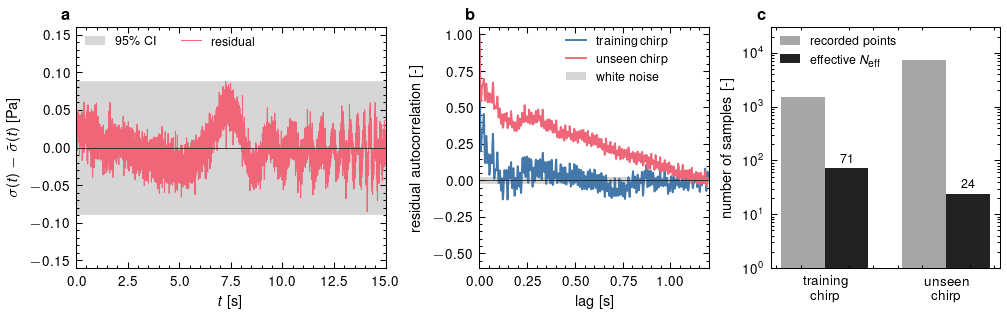

In [15]:
def make_fig4():
    use_style()
    o = DISC
    col = {"train": BLUE, "test": RED}
    lab = {"train": "training chirp", "test": "unseen chirp"}
    fig, ax = plt.subplots(1, 3, figsize=(DOUBLE, 2.1), constrained_layout=True,
                           gridspec_kw=dict(width_ratios=[1.35, 1, 1]))
    # (a) residuals of the unseen chirp, constant offset removed, with the predictive band
    a = ax[0]; d = o["test"]
    a.fill_between(d["t"], -2 * d["sd"], 2 * d["sd"], color=GREY, alpha=0.6, lw=0, label=r"95\% CI")
    a.plot(d["t"], d["r"] - d["offset"], color=RED, lw=0.5, label="residual")
    a.axhline(0, color=INK, lw=0.4)
    a.set(xlabel=r"$t$ [s]", ylabel=r"$\sigma(t)-\bar\sigma(t)$ [Pa]", xlim=(0, d["t"].max()), ylim=(-0.16, 0.16))
    a.legend(loc="upper left", ncol=2)
    panel(a, "a")
    # (b) residual autocorrelation
    b = ax[1]
    for k in ("train", "test"):
        dd = o[k]; lag = np.arange(dd["rho"].size) * dd["dt"]
        b.plot(lag, dd["rho"], color=col[k], lw=0.9, label=lab[k])
    band = 2 / np.sqrt(o["test"]["n"])
    b.axhspan(-band, band, color=GREY, alpha=0.6, lw=0, label="white noise")
    b.axhline(0, color=INK, lw=0.4)
    b.set(xlabel=r"lag [s]", ylabel=r"residual autocorrelation [-]", xlim=(0, 1.2), ylim=(-0.6, 1.05))
    b.legend(loc="upper center", bbox_to_anchor=(0.6, 1.0))
    panel(b, "b")
    # (c) nominal vs effective number of independent samples
    c = ax[2]
    x = np.arange(2); w = 0.36
    c.bar(x - w / 2, [o[k]["n"] for k in ("train", "test")], w, color="0.65", lw=0, label="recorded points")
    c.bar(x + w / 2, [o[k]["n_eff"] for k in ("train", "test")], w, color=INK, lw=0, label=r"effective $N_{\rm eff}$")
    for xi, k in zip(x, ("train", "test")):
        c.text(xi + w / 2, o[k]["n_eff"] * 1.3, f"{o[k]['n_eff']:.0f}", ha="center", fontsize=6)
    c.set_xticks(x, ["training\nchirp", "unseen\nchirp"]); c.tick_params(axis="x", length=0)
    c.set(yscale="log", ylabel=r"number of samples [-]", ylim=(1, 3e4))
    c.legend(loc="upper left")
    panel(c, "c")
    save(fig, "fig_model_discrepancy")
    return fig


show(make_fig4())

---
# Figure 5. Shampoo formulations: fingerprint space and uncertainty-aware classification

**Data.** The open liquid-formulation dataset of Chitre et al. (*Sci. Data* 2024, CC0; `data/Chitre2024_LiquidFormulationsDataset.json`): 812 shampoo formulations, each with the concentrations of 18 ingredients and a phase-stability label. The 294 stable formulations also have a steady-shear flow curve (25 °C, 1–1000 s⁻¹, mean viscosity and standard deviation of at least three repeats) and a rheology class (Newtonian, shear-thinning, other non-Newtonian).

**Steps.**
1. **Fingerprint space.** Each flow curve is interpolated in log–log space onto a common grid of 30 shear rates, and principal component analysis (PCA) of $\log_{10}\eta(\dot\gamma)$ gives the coordinates of every formulation. PC₁ is oriented along increasing viscosity.
2. **Composition features.** The 18 ingredient concentrations are standardized to zero mean and unit variance.
3. **Shear thinning from composition.** A GP classifier (constant × anisotropic RBF kernel) predicts shear-thinning versus Newtonian from composition alone, for the stable formulations of these two classes, with 5-fold stratified cross-validation.
4. **Phase stability from composition.** A GP classifier (constant × isotropic RBF) predicts stability for all 812 formulations, again 5-fold cross-validated. Calibration is checked with a reliability diagram (five probability bins) and the Brier score, against the baseline of always predicting the stable fraction.

The cross-validated predictions take a few seconds and are stored in `results/shampoo_gpc.pkl`.

In [16]:
from sklearn.decomposition import PCA
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, brier_score_loss

CHITRE_JSON = os.path.join(DATA_DIR, "Chitre2024_LiquidFormulationsDataset.json")
SHAMPOO_CACHE = os.path.join(RESULTS, "shampoo_gpc.pkl")
GRID = np.logspace(0.05, 2.95, 30)                       # common shear-rate grid, s^-1
TYPE_COL = {"NEWTONIAN": BLUE, "SHEAR-THIN": RED, "OTHER": YELLOW}
TYPE_LAB = {"NEWTONIAN": "Newtonian", "SHEAR-THIN": "shear-thinning", "OTHER": "other non-Newtonian"}


def load_flow_curves():
    """Flow curves of the stable formulations (viscosity converted from mPa s to Pa s)."""
    out = []
    for x in json.load(open(CHITRE_JSON)):
        if not x["Stability_Test"] or not x["Rheology_Data"]:
            continue
        num = lambda v: np.array([np.nan if (q is None or q == "None") else float(q) for q in v])
        rd = {k: num(v) for item in x["Rheology_Data"] for k, v in item.items()}
        ok = np.isfinite(rd["shear_rate"]) & np.isfinite(rd["avg_viscosity"]) & (rd["avg_viscosity"] > 0)
        out.append(dict(id=x["ID"], type=x["Rheology_Type"], gd=rd["shear_rate"][ok],
                        eta=rd["avg_viscosity"][ok] * 1e-3, sd=rd["std_dev"][ok] * 1e-3))
    return out


def composition():
    """Standardized ingredient concentrations and stability labels of all formulations."""
    d = json.load(open(CHITRE_JSON))
    skip = {"Stability_Test", "Turbidity_NTU", "Turbidity_Error", "Viscosity", "Rheology_Type", "Rheology_Data", "ID"}
    ingr = [k for k in d[0] if k not in skip]
    X = np.array([[x[k] for k in ingr] for x in d], float)
    X = (X - X.mean(0)) / X.std(0)
    y = np.array([int(x["Stability_Test"]) for x in d])
    ids = np.array([x["ID"] for x in d])
    return X, y, ids, ingr


def shampoo_analysis():
    if os.path.exists(SHAMPOO_CACHE):
        return pickle.load(open(SHAMPOO_CACHE, "rb"))
    curves = load_flow_curves()
    # 1. PCA fingerprint space of log10 viscosity on the common grid
    Y = np.array([np.interp(np.log(GRID), np.log(x["gd"]), np.log10(x["eta"])) for x in curves])
    pca = PCA(5).fit(Y); Z = pca.transform(Y)
    if np.corrcoef(Z[:, 0], Y.mean(1))[0, 1] < 0:          # orient PC1 along increasing viscosity
        Z[:, 0] *= -1; pca.components_[0] *= -1
    types = np.array([x["type"] for x in curves])
    # 2. composition features
    X, y, ids, ingr = composition()
    row = {i: k for k, i in enumerate(ids)}
    Xs = np.array([X[row[c["id"]]] for c in curves])
    skf = StratifiedKFold(5, shuffle=True, random_state=0)
    # 3. shear thinning vs Newtonian from composition
    k = types != "OTHER"; yt = (types[k] == "SHEAR-THIN").astype(int)
    p_thin = np.full(len(curves), np.nan)
    p_thin[k] = cross_val_predict(GaussianProcessClassifier(C(1.0) * RBF(np.ones(X.shape[1])), random_state=0),
                                  Xs[k], yt, cv=skf, method="predict_proba")[:, 1]
    # 4. phase stability from composition
    p_stab = cross_val_predict(GaussianProcessClassifier(C(1.0) * RBF(3.0), random_state=0), X, y, cv=skf,
                               method="predict_proba")[:, 1]
    out = dict(Z=Z, evr=pca.explained_variance_ratio_, comps=pca.components_, types=types, p_thin=p_thin, y_thin=yt,
               auc_thin=roc_auc_score(yt, p_thin[k]), p_stab=p_stab, y_stab=y,
               auc_stab=roc_auc_score(y, p_stab), brier=brier_score_loss(y, p_stab),
               brier_ref=brier_score_loss(y, np.full_like(p_stab, y.mean())))
    pickle.dump(out, open(SHAMPOO_CACHE, "wb"))
    return out


SHAMPOO = shampoo_analysis()
o = SHAMPOO
print(f"PCA explained variance: PC1 {100 * o['evr'][0]:.1f}%, PC2 {100 * o['evr'][1]:.1f}%")
print(f"shear thinning from composition: AUC {o['auc_thin']:.3f}")
print(f"stability from composition: AUC {o['auc_stab']:.3f}, Brier {o['brier']:.3f} (baseline {o['brier_ref']:.3f})")

PCA explained variance: PC1 97.9%, PC2 1.3%
shear thinning from composition: AUC 0.900
stability from composition: AUC 0.875, Brier 0.138 (baseline 0.231)


**Panels.** (a) the PCA plane colored by the measured rheology class, with the PC loadings against shear rate in the inset; (b) the same plane colored by the cross-validated probability of shear thinning predicted from composition (gray: other non-Newtonian, not classified); (c) reliability diagram of the stability classifier: mean predicted probability against the observed stable fraction in each bin, with $\pm2$ standard errors and the number of formulations per bin.

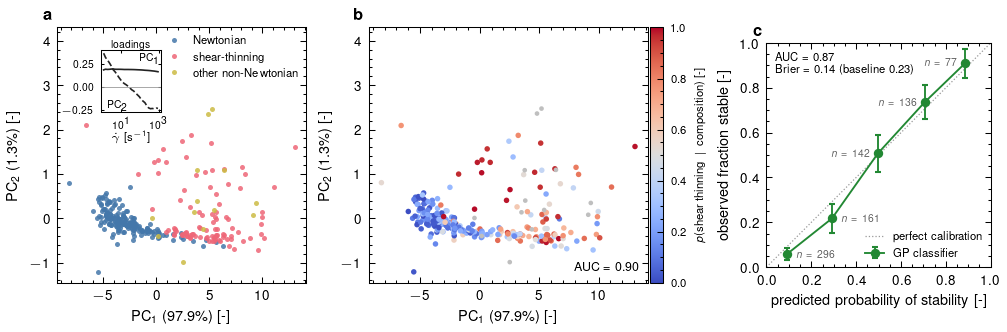

In [17]:
def make_fig5():
    use_style()
    o = SHAMPOO
    ylim = (-1.45, 4.3)          # empty band above the data for the loadings inset and the legend
    fig, ax = plt.subplots(1, 3, figsize=(DOUBLE, 2.2), constrained_layout=True,
                           gridspec_kw=dict(width_ratios=[1, 1.12, 0.9]))
    xl = rf"PC$_1$ ({100 * o['evr'][0]:.1f}\%) [-]"; yl = rf"PC$_2$ ({100 * o['evr'][1]:.1f}\%) [-]"
    # (a) fingerprint space, measured class
    a = ax[0]
    for t in ("NEWTONIAN", "SHEAR-THIN", "OTHER"):
        k = o["types"] == t
        a.plot(o["Z"][k, 0], o["Z"][k, 1], "o", color=TYPE_COL[t], ms=2.4, alpha=0.85, mec="none", label=TYPE_LAB[t])
    a.set(xlabel=xl, ylabel=yl, ylim=ylim); a.legend(loc="upper right", fontsize=5.5, borderaxespad=0.3)
    ins = a.inset_axes([0.175, 0.67, 0.24, 0.24])
    ins.plot(GRID, o["comps"][0], color=INK, lw=0.8, label="PC$_1$")
    ins.plot(GRID, o["comps"][1], color=INK, lw=0.8, ls="--", label="PC$_2$")
    ins.axhline(0, color="0.6", lw=0.4); ins.set_xscale("log"); ins.minorticks_off()
    ins.tick_params(labelsize=5, length=1.5, which="both")
    ins.set_xlabel(r"$\dot\gamma$ [s$^{-1}$]", fontsize=5.5, labelpad=0)
    ins.set_title("loadings", fontsize=5, pad=1.5)
    ins.text(300, 0.25, "PC$_1$", fontsize=5, ha="center", va="bottom")
    ins.text(1.6, -0.2, "PC$_2$", fontsize=5, ha="left", va="center")
    panel(a, "a")
    # (b) same plane, colored by p(shear thinning | composition)
    b = ax[1]
    k = ~np.isnan(o["p_thin"])
    sc = b.scatter(o["Z"][k, 0], o["Z"][k, 1], c=o["p_thin"][k], cmap="coolwarm", vmin=0, vmax=1, s=7, edgecolors="none")
    b.scatter(o["Z"][~k, 0], o["Z"][~k, 1], c="0.75", s=5, edgecolors="none")
    cb = fig.colorbar(sc, ax=b, pad=0.01, fraction=0.05)
    cb.set_label(r"$p(\mathrm{shear\ thinning}\mid\mathrm{composition})$ [-]", fontsize=5.5)
    cb.ax.tick_params(labelsize=5.5)
    b.text(0.97, 0.05, rf"AUC $={o['auc_thin']:.2f}$", transform=b.transAxes, ha="right", fontsize=6)
    b.set(xlabel=xl, ylabel=yl, ylim=ylim)
    panel(b, "b")
    # (c) reliability of stability predictions
    c = ax[2]
    bins = np.linspace(0, 1, 6); idx = np.clip(np.digitize(o["p_stab"], bins[1:-1]), 0, 4)
    pm = np.array([o["p_stab"][idx == j].mean() for j in range(5)])
    fo = np.array([o["y_stab"][idx == j].mean() for j in range(5)])
    nn = np.array([(idx == j).sum() for j in range(5)])
    se = np.sqrt(fo * (1 - fo) / nn)
    c.plot([0, 1], [0, 1], color="0.6", lw=0.6, ls=":", label="perfect calibration")
    c.errorbar(pm, fo, yerr=2 * se, fmt="o-", color=GREEN, ms=3.5, lw=0.9, capsize=1.5, label="GP classifier")
    for x_, y_, n_ in zip(pm, fo, nn):          # label on the side of the point away from the diagonal
        above = y_ > x_
        c.text(x_ - 0.04 if above else x_ + 0.04, y_, f"$n={n_}$", fontsize=5, color="0.4",
               ha="right" if above else "left", va="center")
    c.set(xlim=(0, 1), ylim=(0, 1), xlabel="predicted probability of stability [-]", ylabel="observed fraction stable [-]")
    c.set_aspect("equal")
    c.text(0.04, 0.96, rf"AUC $={o['auc_stab']:.2f}$" "\n" rf"Brier $={o['brier']:.2f}$ (baseline {o['brier_ref']:.2f})",
           transform=c.transAxes, va="top", fontsize=5.5)
    c.legend(loc="lower right", fontsize=5.5)
    panel(c, "c")
    save(fig, "fig_shampoo_ml")
    return fig


show(make_fig5())

---
# Figure 6. A spectrum from a restricted window, and the value of the next experiment

**Question addressed.** SAOS of polystyrene at 145 °C covers about five decades of frequency. A relaxation spectrum calibrated on that window says little about times longer than $1/\omega_{\min}$, which is exactly where the zero-shear viscosity $\eta_0$ and long-time creep are decided. The figure quantifies that uncertainty and ranks candidate follow-up experiments by how much they are expected to reduce it.

**Model and inference.** The eleven-mode generalized Maxwell spectrum and its two nested-sampling calibrations (SAOS alone; SAOS + creep) defined in *Shared models*. The two runs take about 4.5 min together; the posterior samples are stored in `results/fig2_gm/`.

In [18]:
GM_SAOS, GM_BOTH = gm_run(False), gm_run(True)
for name, r in (("SAOS only", GM_SAOS), ("SAOS + creep", GM_BOTH)):
    eta0 = (10 ** r["samples"][:, :TAU.size] * TAU).sum(1)
    lo, med, hi = np.percentile(eta0, [2.5, 50, 97.5]) / 1e6
    print(f"{name:13s}: eta0 = {med:.1f} MPa s (95% interval {lo:.1f}-{hi:.1f}), ln Z = {r['logz']:.1f}")

SAOS only    : eta0 = 296.6 MPa s (95% interval 17.9-869.9), ln Z = 86.6
SAOS + creep : eta0 = 18.6 MPa s (95% interval 12.4-79.4), ln Z = 112.1


**Expected information gain.** For each of the five candidate experiments (*Shared models*), the expected information gain (EIG) on $\log_{10}\eta_0$ is estimated from the SAOS-only posterior of the spectrum: 3000 posterior samples predict the log-observables; 200 of them are taken as hypothetical truths, an outcome with 10 % scatter is simulated, the samples are reweighted by its likelihood, and the reduction in entropy of $\log_{10}\eta_0$ under a Gaussian approximation, $\tfrac12\log_2(\mathrm{Var}_{\rm before}/\mathrm{Var}_{\rm after})$, is averaged over outcomes (`expected_gain`). To show the sampling variability, every candidate is evaluated on four independent nested-sampling runs: the main run and three repeats with 1500 live points and seeds 0–2.

The **realized gain** of the 2 h creep test that was actually measured is the same entropy reduction computed between the SAOS-only and the SAOS + creep posteriors, for all 4 × 4 combinations of independent runs. Computing everything in this cell from scratch, including the six repeat runs, takes about 40 min; the EIG values and realized gains are stored in `results/fig_gm_design.pkl`.

In [19]:
EIG_CACHE = os.path.join(RESULTS, "fig_gm_design.pkl")
N_SAMPLES, N_OUT = 3000, 200
SAOS_RUNS = [(False, None), (False, 0), (False, 1), (False, 2)]     # (use_creep, seed): main run + 3 repeats
BOTH_RUNS = [(True, None), (True, 0), (True, 1), (True, 2)]
KIND_COLOR = {"saos": INK, "creep": GREEN, "relax": PURPLE}


def run_name(use_creep, seed):
    return f"T{GM_T}_liquid_{'both' if use_creep else 'saos'}" + ("" if seed is None else f"_nl1500_s{seed}")


def gm_run_named(use_creep, seed):
    return gm_run(use_creep, nlive=600 if seed is None else 1500, seed=seed)


def log_eta0(samples):
    return np.log10((10 ** samples[:, :TAU.size] * TAU).sum(1))


def gm_observable(kind, G, x):
    if kind == "saos":
        a, b = gm_moduli(G, TAU, x); return np.log(np.r_[a, b])
    if kind == "creep":
        return np.log(gm_creep(G, TAU, x))
    return np.log(gm_relax(G, TAU, x))


def gm_eig(samples, kind, x, seed=0):
    """Expected information gain on log10 eta0 [bits] for one candidate, from spectrum samples."""
    Y = np.array([gm_observable(kind, 10 ** th[:TAU.size], x) for th in samples])
    return expected_gain(Y, log_eta0(samples), N_OUT, seed)


def eig_analysis():
    if os.path.exists(EIG_CACHE):
        return pickle.load(open(EIG_CACHE, "rb"))
    prot = protocols(GM_D["saos"]["w"])
    out = dict(protocols={lab: (kind, duration(kind, x)) for lab, (kind, x) in prot.items()}, eig={})
    q_before = {}
    for r, (uc, s) in enumerate(SAOS_RUNS):
        smp = gm_run_named(uc, s)["samples"]
        smp = smp[np.random.default_rng(r).choice(len(smp), min(N_SAMPLES, len(smp)), replace=False)]
        q_before[run_name(uc, s)] = log_eta0(smp)
        out["eig"][run_name(uc, s)] = {lab: gm_eig(smp, kind, x, seed=k) for k, (lab, (kind, x)) in enumerate(prot.items())}
    q_after = {run_name(uc, s): log_eta0(gm_run_named(uc, s)["samples"]) for uc, s in BOTH_RUNS}
    out["realized_creep"] = np.array([0.5 * np.log2(np.var(qb) / np.var(qa))
                                      for qb in q_before.values() for qa in q_after.values()])
    out["creep_minutes"] = float(GM_D["creep_full"]["t"].max()) / 60
    pickle.dump(out, open(EIG_CACHE, "wb"))
    return out


GM_EIG = eig_analysis()
for lab in GM_EIG["protocols"]:
    g = [GM_EIG["eig"][run_name(uc, s)][lab] for uc, s in SAOS_RUNS]
    print(f"{lab.replace(chr(10), ' '):32s} EIG median {np.median(g):.2f} bits (range {min(g):.2f}-{max(g):.2f})")
rz = GM_EIG["realized_creep"]
print(f"{'measured creep, 2 h (realized)':32s}     median {np.median(rz):.2f} bits (range {rz.min():.2f}-{rz.max():.2f})")

more SAOS points (same window)   EIG median 0.03 bits (range 0.02-0.04)
SAOS to $10^{-3}$ rad/s          EIG median 0.53 bits (range 0.35-0.77)
creep, 30 min                    EIG median 0.23 bits (range 0.13-0.39)
creep, 2 h                       EIG median 1.28 bits (range 1.12-1.67)
relaxation, 30 min               EIG median 0.58 bits (range 0.34-0.78)
measured creep, 2 h (realized)       median 1.23 bits (range 0.72-1.75)


**Panels.** (a) measured $G'$, $G''$ and the SAOS-only spectrum (median and 95 % band); the measured window is shaded. (b) creep compliance predicted from SAOS alone (blue), the joint SAOS + creep fit (green) and the measured creep (black); times beyond $1/\omega_{\min}$ are shaded green. (c) EIG on $\eta_0$ against instrument time for the candidates (median and range over the four runs), with the realized gain of the measured 2 h creep test (open diamond) next to its expectation.

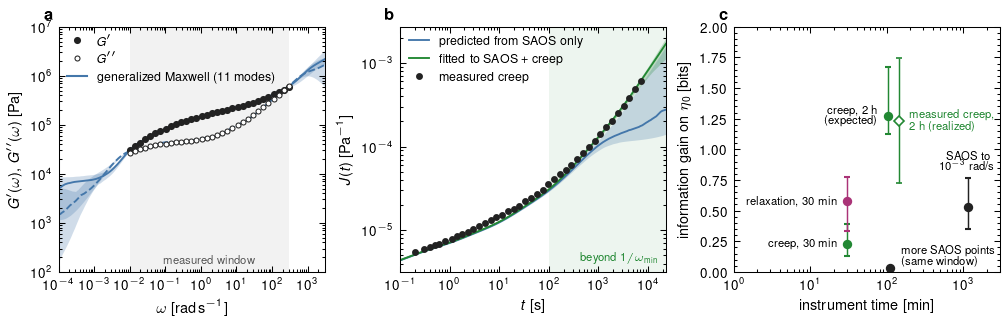

In [20]:
LABELS = {"more SAOS points\n(same window)": ("mid", (5, 1), "left", "bottom"),     # label placement per protocol
          r"SAOS to $10^{-3}$ rad/s": ("top", (0, 3), "center", "bottom"),
          "creep, 30 min": ("mid", (-5, 0), "right", "center"),
          "creep, 2 h": ("mid", (-5, 0), "right", "center"),
          "relaxation, 30 min": ("mid", (-5, 0), "right", "center")}
TEXT = {r"SAOS to $10^{-3}$ rad/s": "SAOS to\n$10^{-3}$ rad/s", "creep, 2 h": "creep, 2 h\n(expected)"}
DODGE = 1.18     # expected and realized 2 h creep are drawn side by side around 2 h


def panel_gm_saos(a, d, rs, letter="a"):
    w = d["saos"]["w"]
    wg = np.logspace(-4, 3.5, 250)
    a.axvspan(w.min(), w.max(), color=GREY, alpha=0.18, lw=0)
    for kind in ("Gp", "Gpp"):
        lo, med, hi = gm_band(rs["samples"], kind, wg)
        a.fill_between(wg, lo, hi, color=BLUE, alpha=0.25, lw=0)
        a.plot(wg, med, color=BLUE, lw=0.9, ls="-" if kind == "Gp" else "--")
    a.plot(w, d["saos"]["Gp"], "o", color=INK, ms=2.4, label=r"$G'$")
    a.plot(w, d["saos"]["Gpp"], "o", mfc="white", mec=INK, mew=0.5, ms=2.4, label=r"$G''$")
    a.plot([], [], color=BLUE, label=f"generalized Maxwell ({TAU.size} modes)")
    a.set(xscale="log", yscale="log", xlim=(1e-4, 3e3), ylim=(1e2, 1e7),
          xlabel=r"$\omega$ [rad\,s$^{-1}$]", ylabel=r"$G'(\omega)$, $G''(\omega)$ [Pa]")
    a.text(np.sqrt(w.min() * w.max()), 1.5e2, "measured window", ha="center", fontsize=5.5, color="0.35")
    a.legend(loc="upper left")
    panel(a, letter)


def panel_gm_creep(b, d, rs, rb, letter="b"):
    w = d["saos"]["w"]; tt = d["creep_full"]["t"]
    tg = np.logspace(-1, np.log10(tt.max()) + 0.5, 250)
    b.axvspan(1 / w.min(), tg[-1], color=GREEN, alpha=0.08, lw=0)
    for r, col, lab in ((rs, BLUE, "predicted from SAOS only"), (rb, GREEN, "fitted to SAOS + creep")):
        lo, med, hi = gm_band(r["samples"], "J", tg)
        b.fill_between(tg, lo, hi, color=col, alpha=0.25, lw=0)
        b.plot(tg, med, color=col, lw=0.9, label=lab)
    b.plot(d["creep"]["t"], d["creep"]["J"], "o", color=INK, ms=2.3, label="measured creep")
    b.set(xscale="log", yscale="log", xlim=(0.1, tg[-1]), xlabel=r"$t$ [s]", ylabel=r"$J(t)$ [Pa$^{-1}$]")
    b.text(0.97, 0.05, r"beyond $1/\omega_{\min}$", transform=b.transAxes, ha="right", fontsize=5.5, color=GREEN)
    b.legend(loc="upper left")
    panel(b, letter)


def panel_eig(c, o, letter="c"):
    for lab, (kind, sec) in o["protocols"].items():
        g = np.array([o["eig"][run_name(uc, s)][lab] for uc, s in SAOS_RUNS]); T = sec / 60
        if lab == "creep, 2 h":
            T /= DODGE
        med = np.median(g)
        c.errorbar(T, med, yerr=[[med - g.min()], [g.max() - med]], fmt="o", color=KIND_COLOR[kind], ms=3.5,
                   elinewidth=0.7, capsize=1.5)
        where, off, ha, va = LABELS[lab]
        c.annotate(TEXT.get(lab, lab), (T, g.max() if where == "top" else med), xytext=off, textcoords="offset points",
                   fontsize=5.5, ha=ha, va=va, linespacing=1.0)
    rz = o["realized_creep"]; med = np.median(rz); T = o["creep_minutes"] * DODGE
    c.errorbar(T, med, yerr=[[med - rz.min()], [rz.max() - med]], fmt="D", mfc="white", mec=GREEN,
               color=GREEN, ms=3.2, mew=0.8, elinewidth=0.7, capsize=1.5)
    c.annotate("measured creep,\n2 h (realized)", (T, med), xytext=(5, 0), textcoords="offset points",
               fontsize=5.5, va="center", ha="left", color=GREEN, linespacing=1.0)
    c.set(xscale="log", xlabel="instrument time [min]", ylabel=r"information gain on $\eta_0$ [bits]",
          xlim=(1, 3e3), ylim=(0, 2.0))
    panel(c, letter)


def make_fig6():
    use_style()
    fig, ax = plt.subplots(1, 3, figsize=(DOUBLE, 2.15), constrained_layout=True)
    panel_gm_saos(ax[0], GM_D, GM_SAOS)
    panel_gm_creep(ax[1], GM_D, GM_SAOS, GM_BOTH)
    panel_eig(ax[2], GM_EIG)
    save(fig, "fig_gm_design_T145")
    return fig


show(make_fig6())